OptDMD is a variation of DMD that does better by bypassing the discrete update matrix entirely, and instead solving

$$\min \|X-\Phi(\lambda)B\|_F\quad\text{over}\quad \lambda\in\mathbb{C}^k, B\in\mathbb{C}^{l\times n},$$
where $X\in\mathbb{C}^{m\times n},\Phi(\lambda)\in \mathbb{C}^{m\times l},$ and $\Phi(\lambda)_{i,j}=\exp(\lambda_jt_i)$.

What this means is that rather than finding the optimal update matrix, we find the optimal $b_j,\phi_j,$ and $\lambda_j$ such that the reconstruction
$$x_i\approx\sum_{j=1}^r b_j\phi_j e^{\lambda_jt_i}$$
is as good as possible. This algorithm is clearly solving the same problem as DMD, but does it in a much more effective way.

In [1]:
import numpy as np # Matrix and vector algebra
import matplotlib.pylab as plt # Plotting
import pandas as pd # Tables
from pydmd import BOPDMD, plotter,DMD # BOPDMD/DMD implementation and a helpful plotting function
from tqdm import tqdm # Progress bars
from sklearn.decomposition import PCA # PCA for comparisons
np.set_printoptions(suppress=True,precision=8,linewidth=100000) # Improve print statements
plt.rcParams['figure.dpi']=400 # Use higher resolution figures
plt.rcParams['text.usetex']=True # Use LaTeX in plots

RSE = lambda X,Y: np.sum((Y-np.real(X))**2)/np.sum((Y-np.mean(Y))**2)
# Model reconstruction = X, true data = Y

# Wide field data temporal components
widefielddata = np.load("../Mouse Data/svdTemporalComponents_corr.npy")

# DMD assumes each time point is a column
widefielddata = widefielddata.T

# Normalize to avoid overflow from calculating exponentials of large numbers
SV_norm = np.linalg.norm(widefielddata,keepdims=True)
SV_normalized = widefielddata / SV_norm

optdmd = BOPDMD(svd_rank=10,num_trials=0) # PyDMD's BOPDMD will use OptDMD if num_trials = 0 (which is the default)
optdmd.fit(SV_normalized[:20,:500],np.arange(500))
print("OptDMD RSE: " + str(RSE(optdmd.reconstructed_data,SV_normalized[:20,:500])))

OptDMD RSE: 0.04923082065812628


# Determining correct number of modes

So with fitting the first 500 timepoints of the top 20 temporal components of the widefield data, OptDMD achieves an RSE about 12 times lower than DMD. With a reconstruction error of ~5%, it seems a lot more plausible that the modes and dynamics extracted by OptDMD have a true biological significance compared to the ~59% reconstruction error from the DMD modes and dynamics.

Let's see how many OptDMD modes are needed to get a good reconstruction of our data, and compare this to PCA.

In [2]:
RSEs = np.zeros(50)
for i in tqdm(range(50)):
    optdmd = BOPDMD(svd_rank=i+1,num_trials=0)
    optdmd.fit(SV_normalized[:50,:1000],np.arange(1000))
    RSEs[i] = RSE(optdmd.reconstructed_data,SV_normalized[:50,:1000])

100%|███████████████████████████████████████████| 50/50 [01:30<00:00,  1.80s/it]


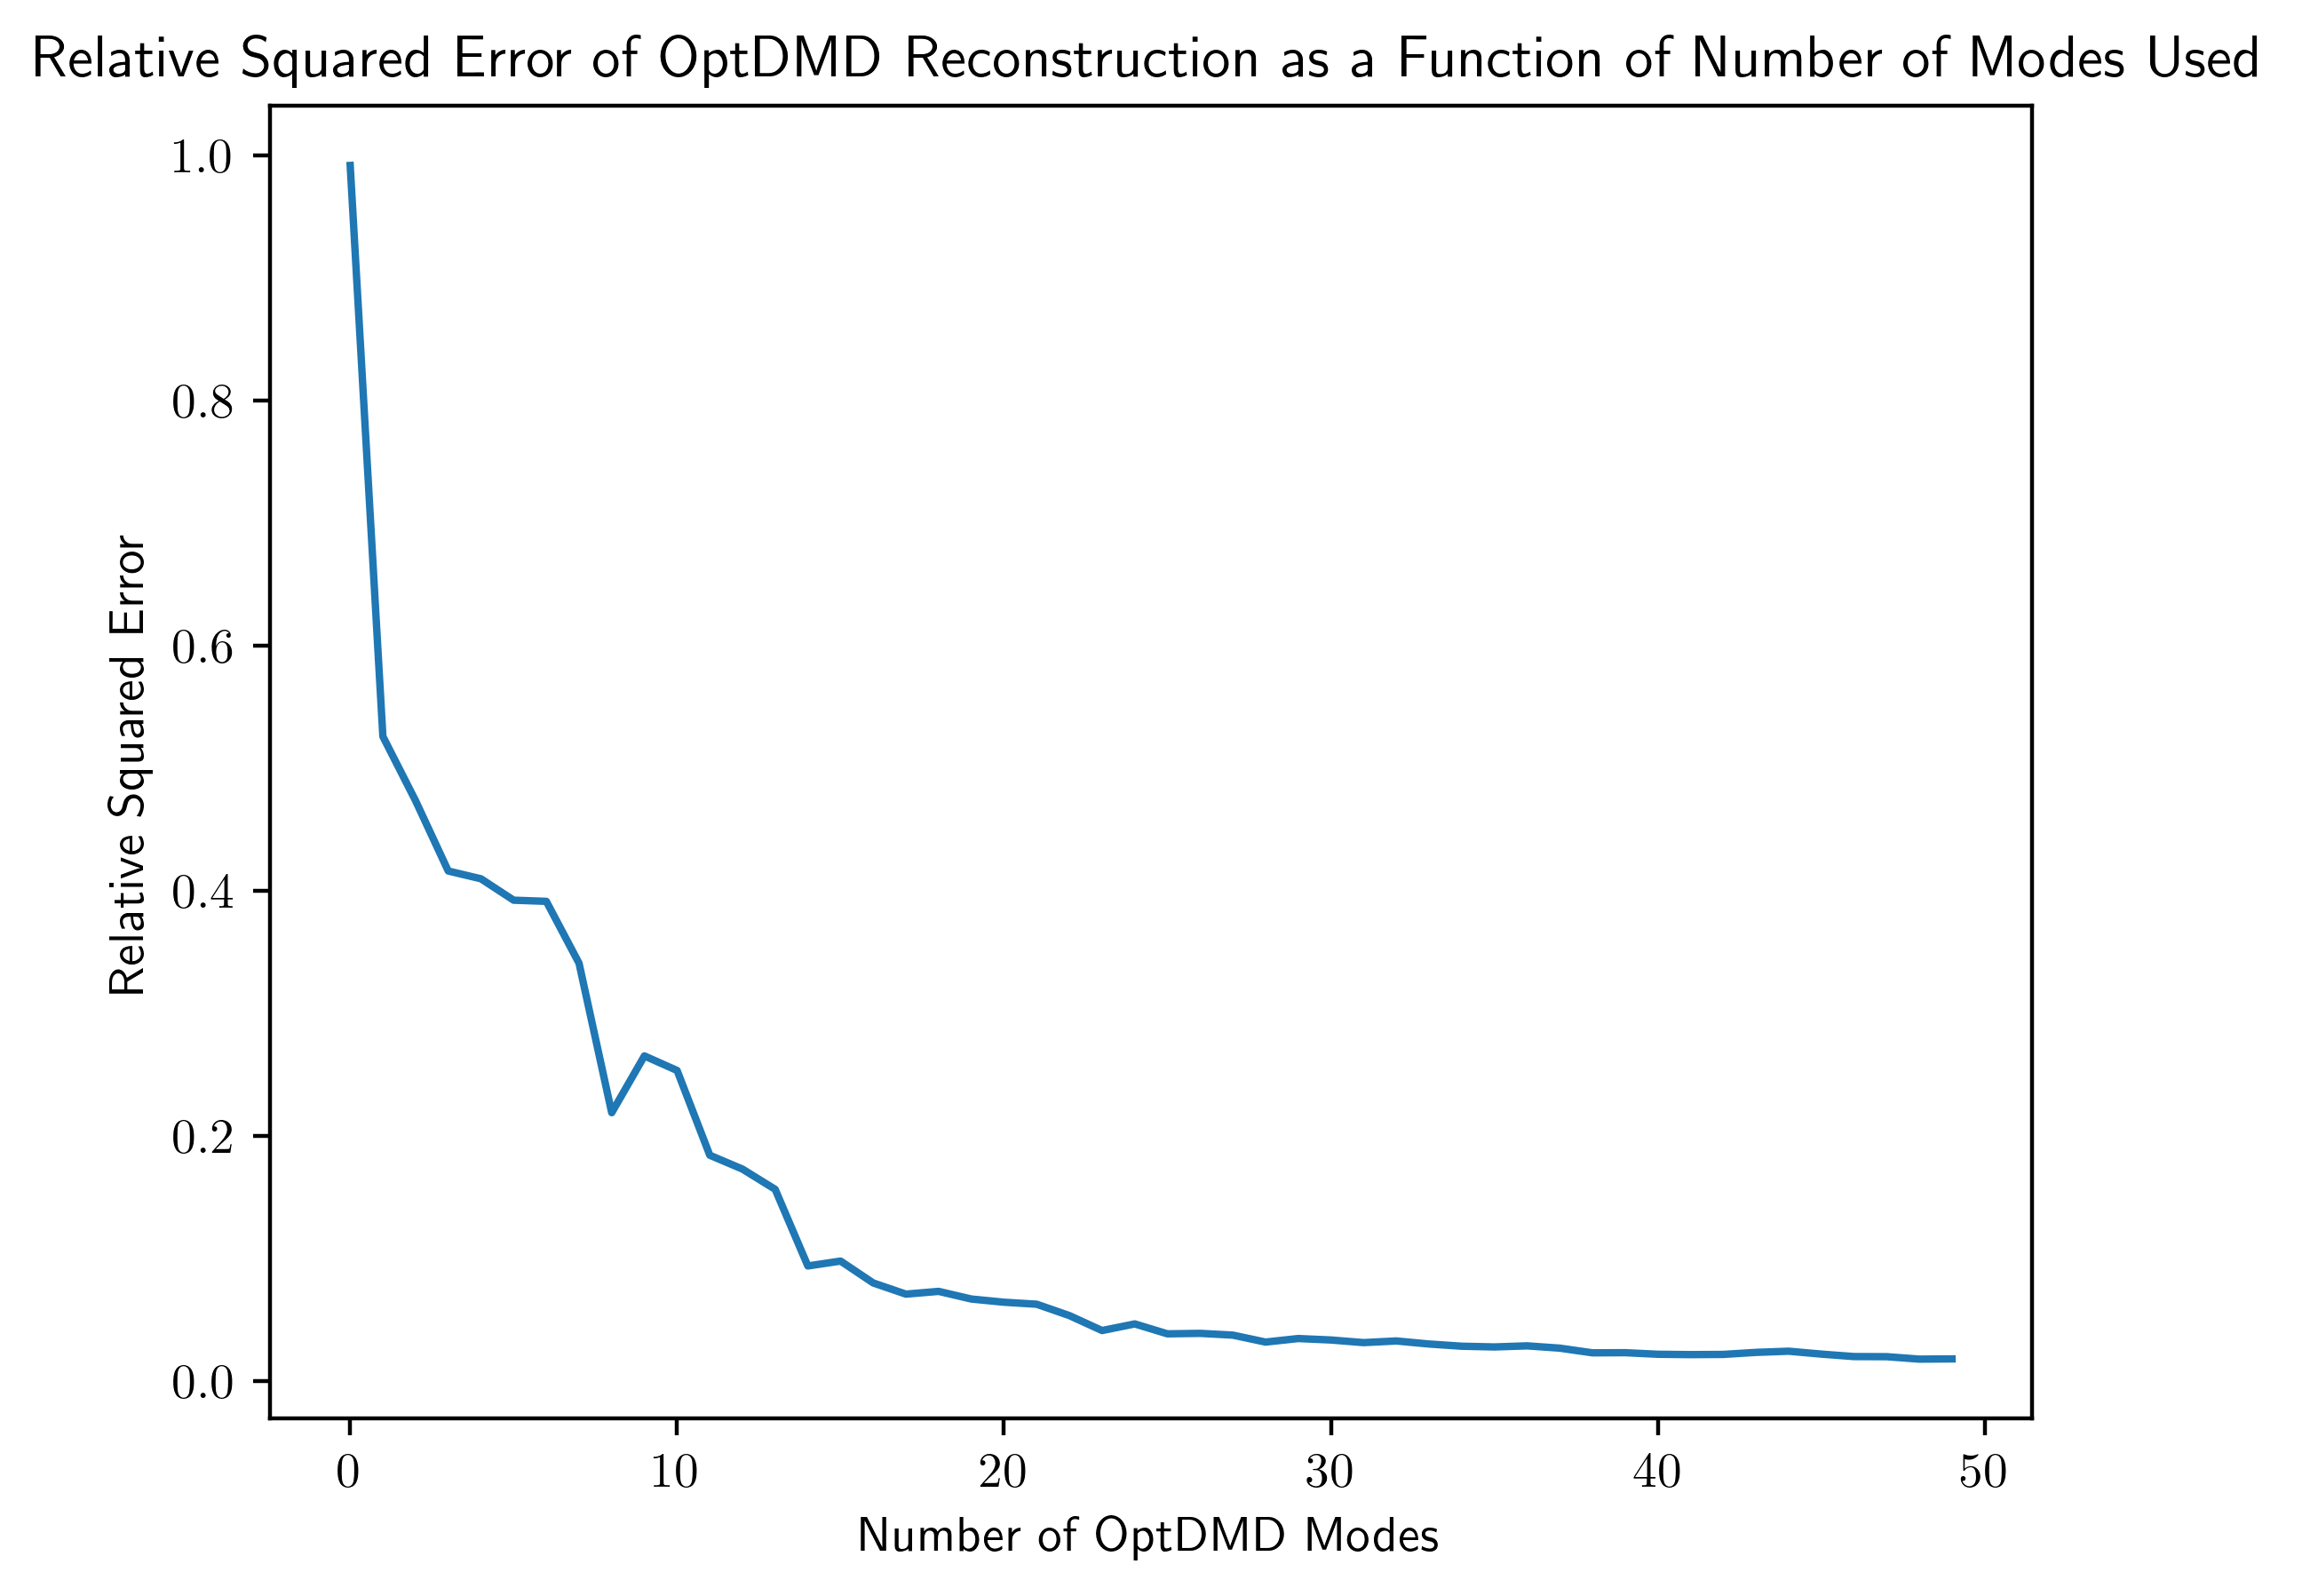

In [3]:
plt.plot(RSEs)
plt.xlabel("Number of OptDMD Modes")
plt.ylabel("Relative Squared Error")
plt.title("Relative Squared Error of OptDMD Reconstruction as a Function of Number of Modes Used");

Text(0.5, 0, 'Number of PCA Components Used')

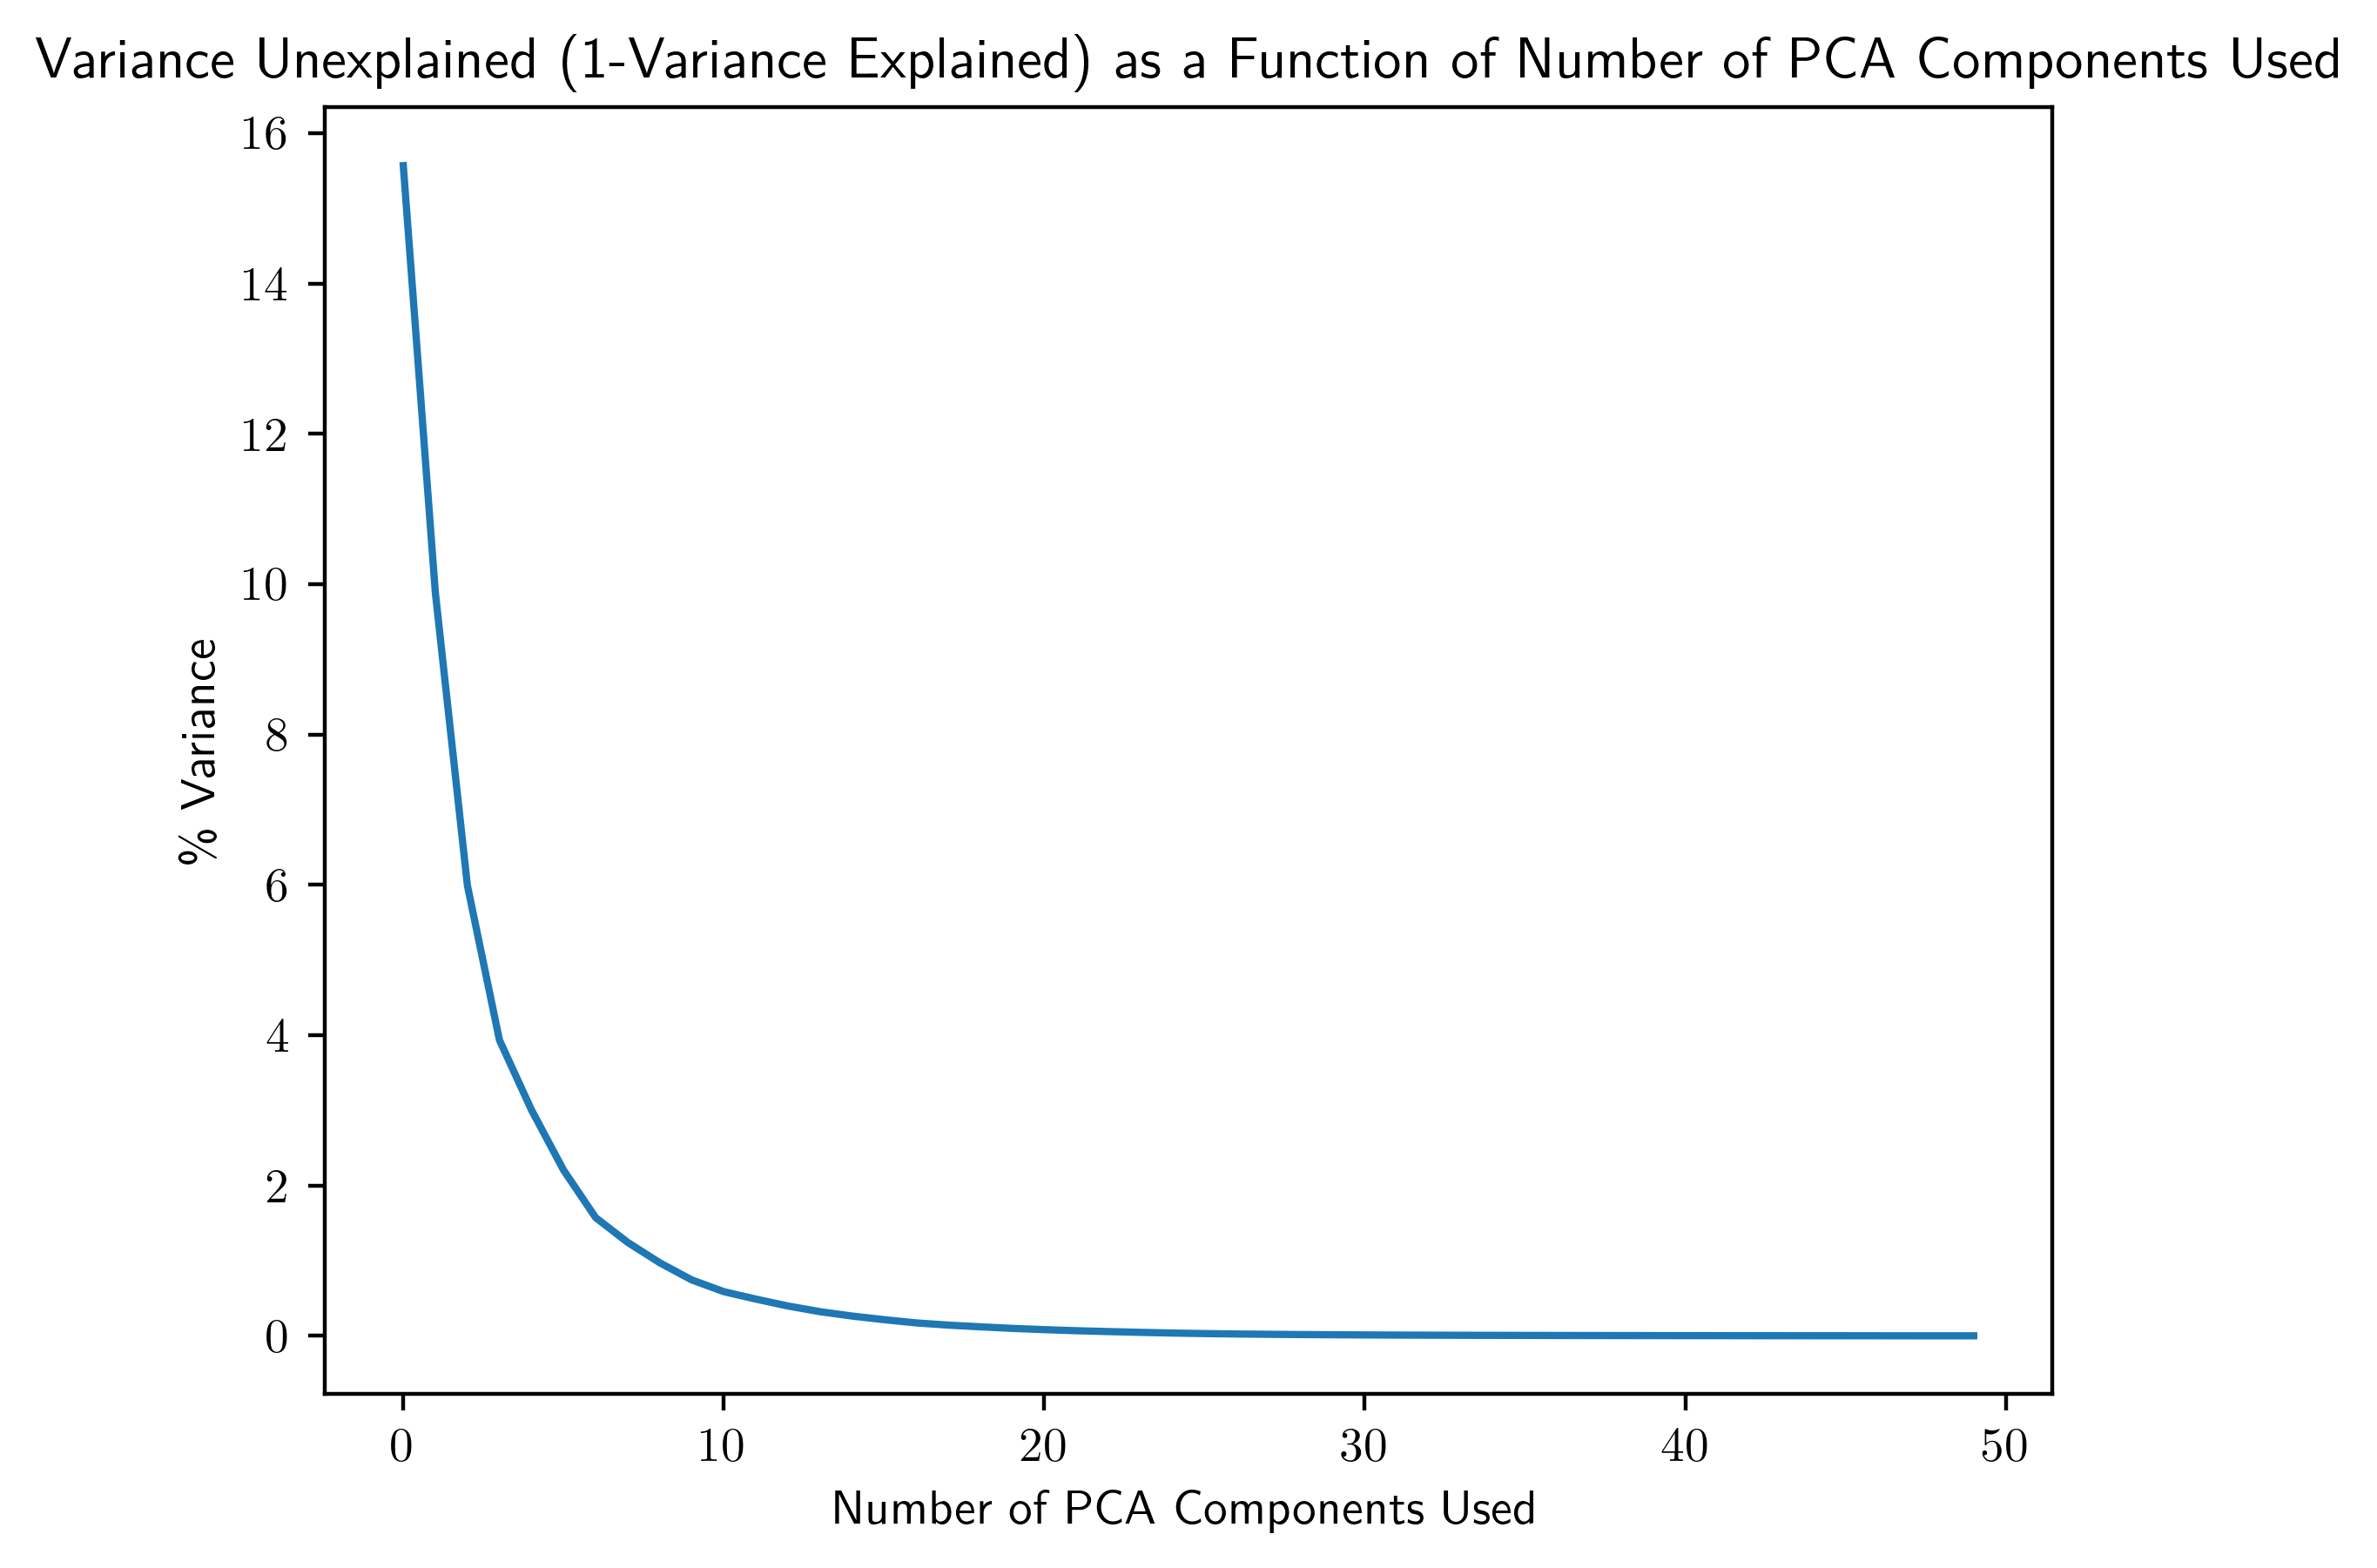

In [4]:
pca = PCA().fit(SV_normalized[:50,:1000])
plt.plot(100*(1-np.cumsum(pca.explained_variance_ratio_)))
plt.title("Variance Unexplained (1-Variance Explained) as a Function of Number of PCA Components Used")
plt.ylabel("\% Variance")
plt.xlabel("Number of PCA Components Used")

The graphs have a qualitatively similar structure, suggesting that both OptDMD and PCA make similar predictions about the dimensionality of our data. It looks like 15-20 OptDMD modes is sufficient for a good fit. Let's do 20 and plot the top 10 temporal components vs their OptDMD reconstructions.

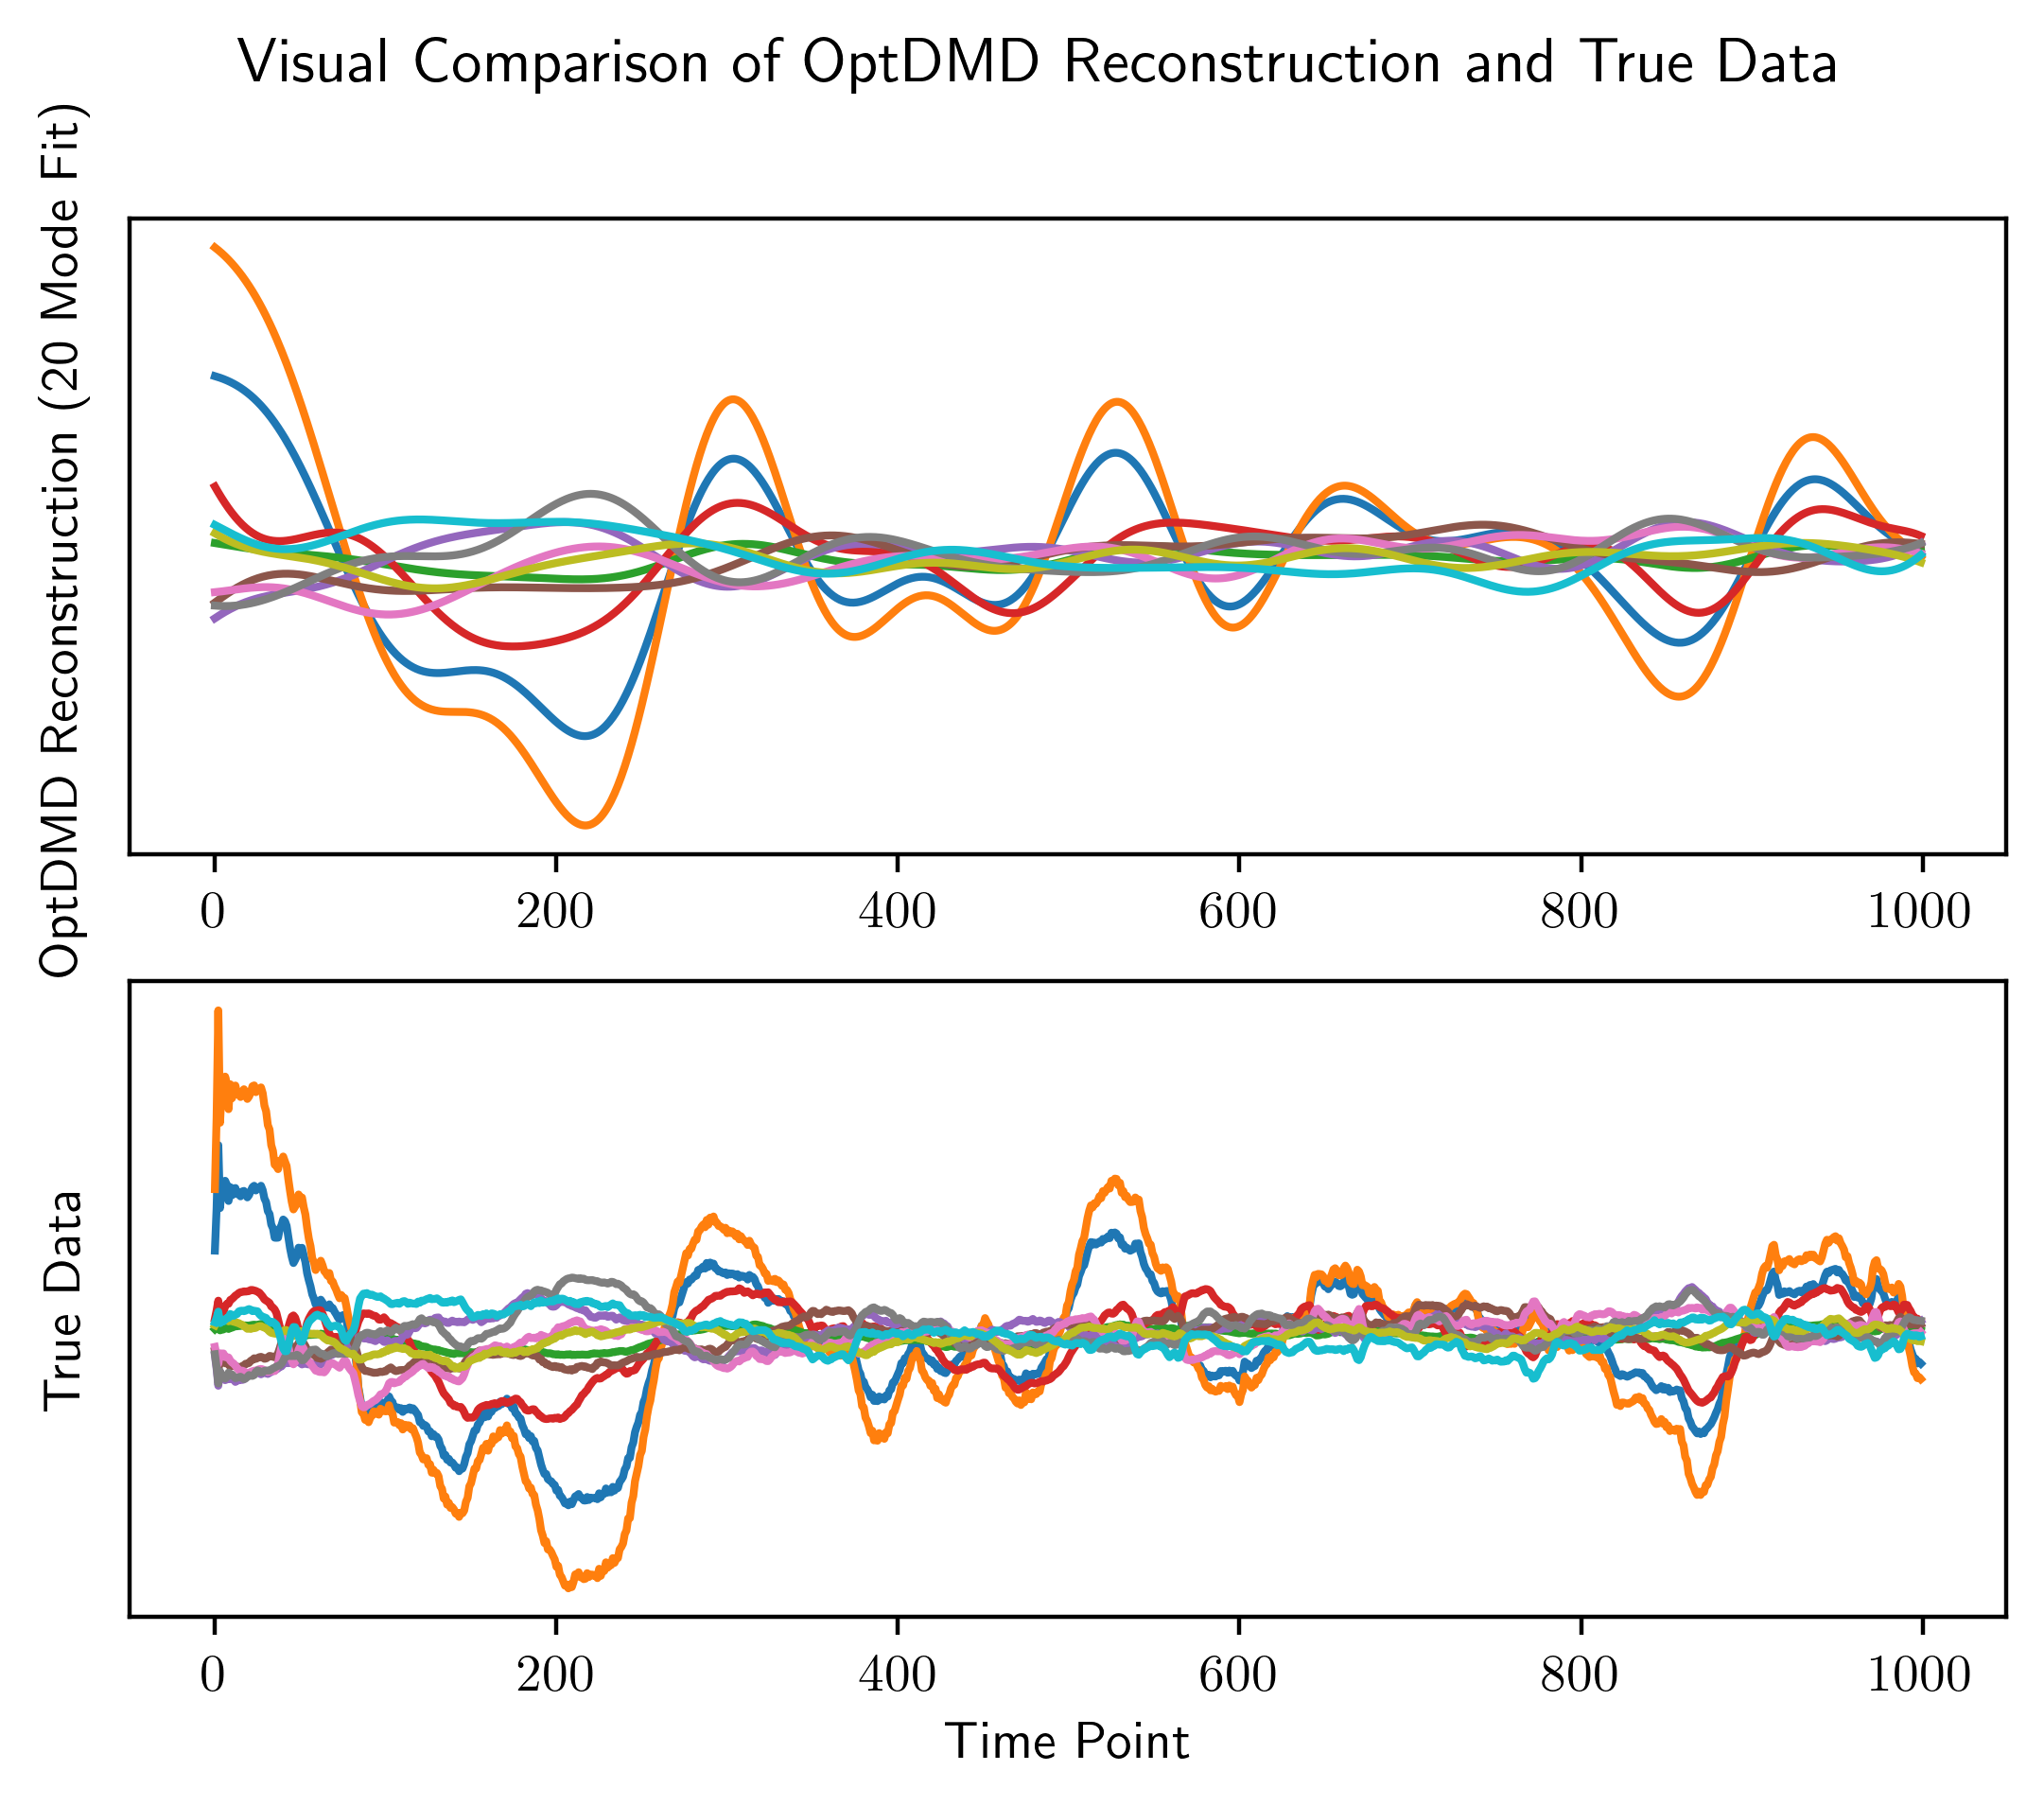

In [5]:
fig,ax = plt.subplots(2,1)
optdmd = BOPDMD(svd_rank=20)
optdmd.fit(SV_normalized[:50,:1000],np.arange(1000))
for i in range(10):
    ax[0].plot(np.real(optdmd.reconstructed_data[i,:]))
    ax[0].set_ylabel("OptDMD Reconstruction (20 Mode Fit)")
    ax[0].set_yticks([])
    ax[1].plot(np.real(SV_normalized[i,:1000]))
    ax[1].set_ylabel("True Data")
    ax[1].set_yticks([])
ax[1].set_xlabel("Time Point")
fig.suptitle("Visual Comparison of OptDMD Reconstruction and True Data");

The fit is clearly much better than in the DMD case. OptDMD does not fit much of the high frequency/transient changes in the data, which could be interpreted as a good thing or a bad thing depending on whether we see those transient changes as true neural transients or just noise.

We can get a lower RSE on a smaller timescale. Let's find the optimal rank for the first 500 time points.

In [7]:
RSEs = np.zeros(50)
for i in tqdm(range(50)):
    optdmd = BOPDMD(svd_rank=i+1,num_trials=0)
    optdmd.fit(SV_normalized[:50,:500],np.arange(500))
    RSEs[i] = RSE(optdmd.reconstructed_data,SV_normalized[:50,:500])

100%|███████████████████████████████████████████| 50/50 [00:47<00:00,  1.05it/s]


Text(0.5, 1.0, 'Relative Squared Error of OptDMD Reconstruction as a Function of Number of Modes Used')

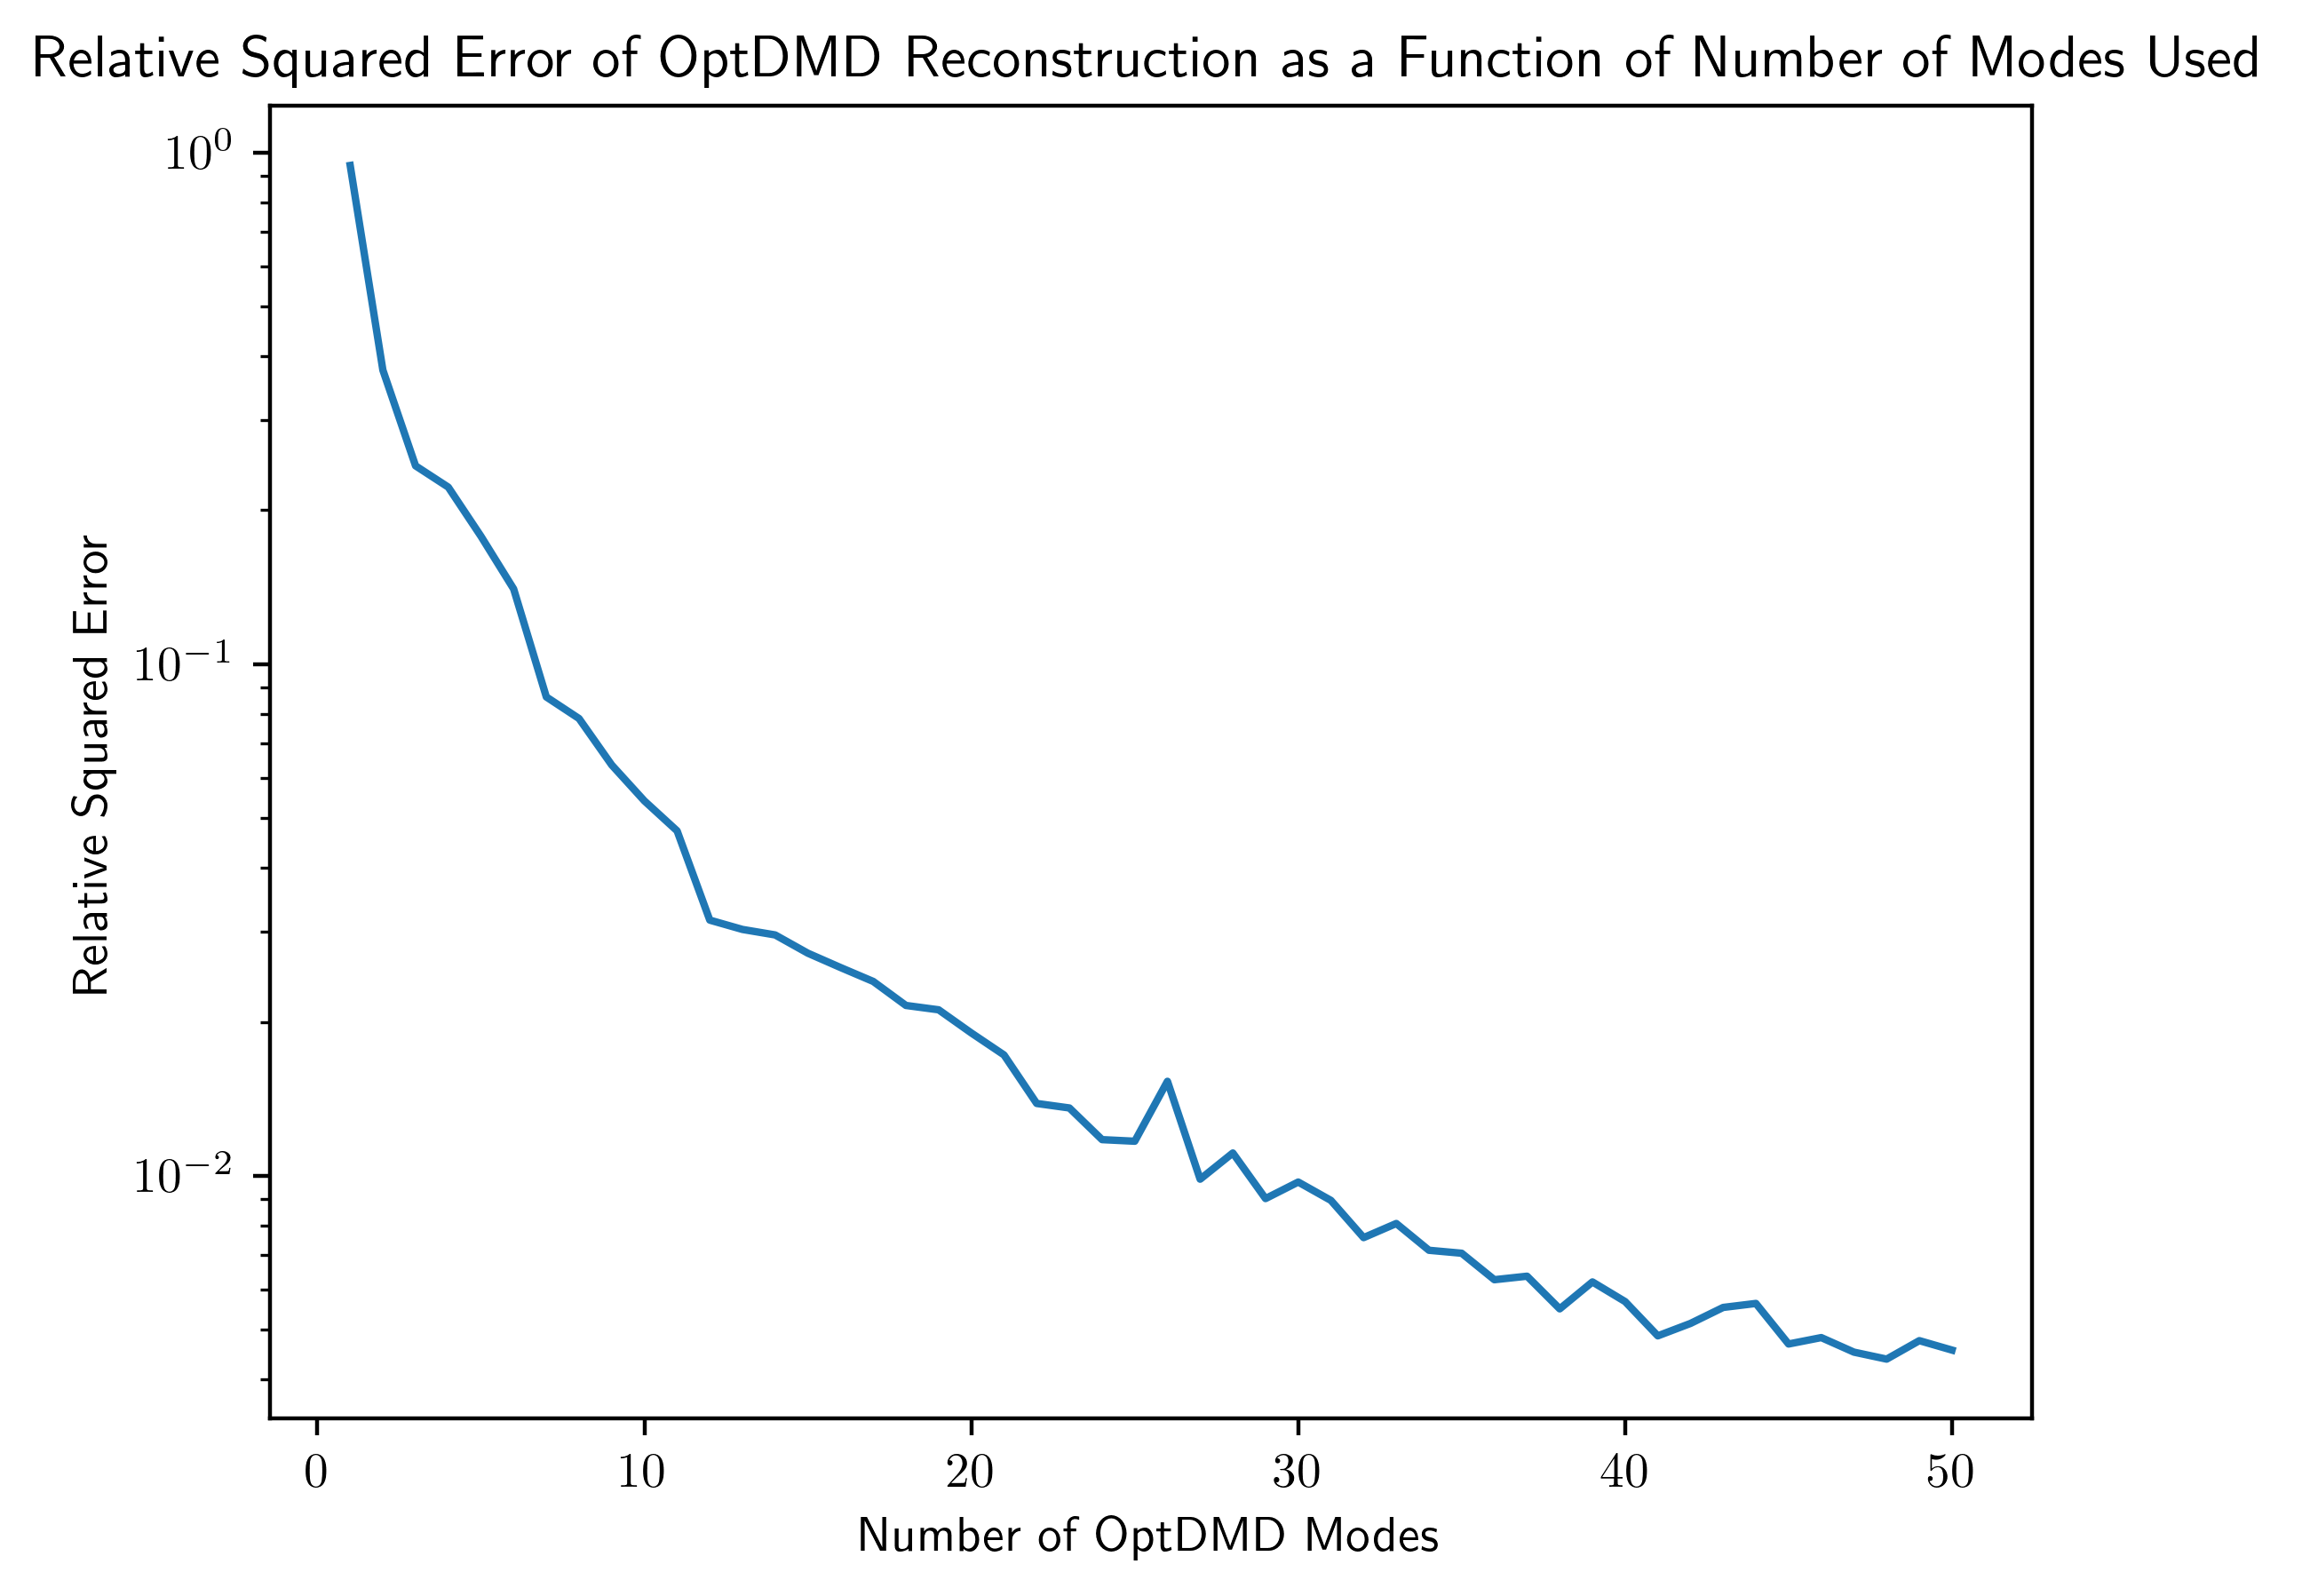

In [8]:
plt.plot(np.arange(1,51),RSEs)
plt.xlabel("Number of OptDMD Modes")
plt.ylabel("Relative Squared Error")
plt.yscale('log')
plt.title("Relative Squared Error of OptDMD Reconstruction as a Function of Number of Modes Used")

Components 0-10 seem to be where the rate of error shrinkage is greatest, although the error still decreases exponentially as a function of the number of OptDMD modes (as it is linear on the log scale). Let's plot the 10 mode and 50 mode reconstructions.

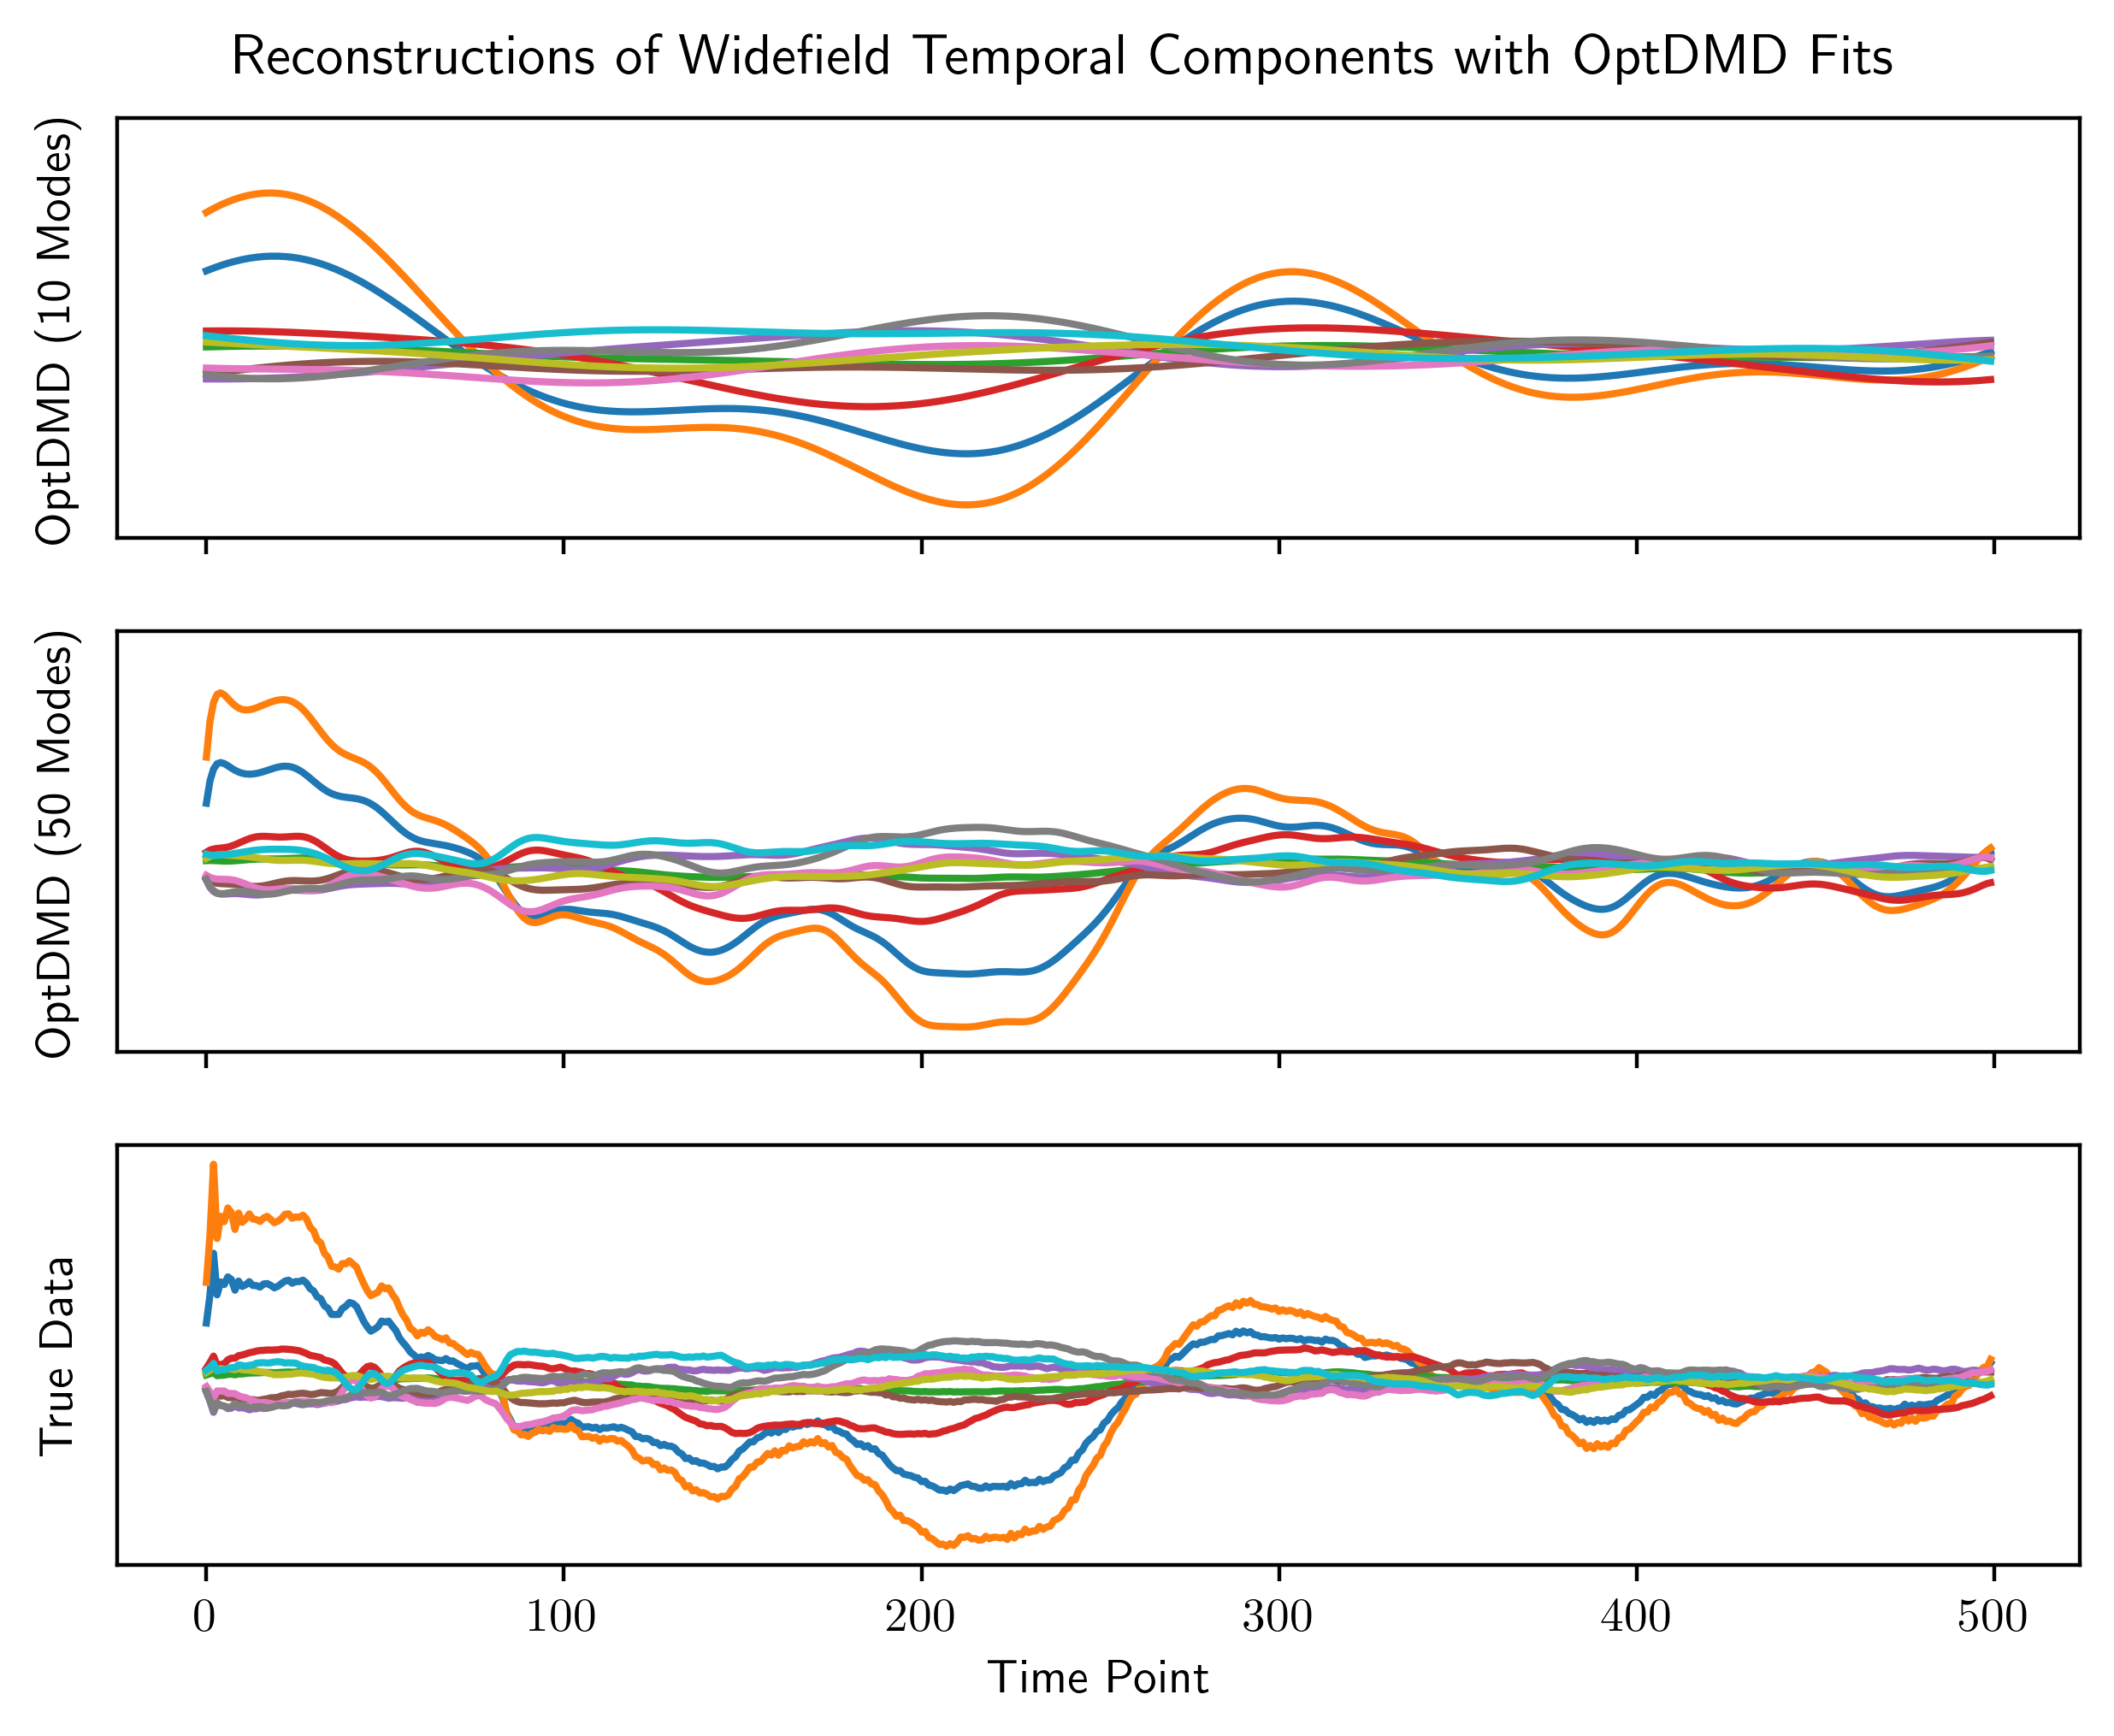

In [9]:
fig,ax = plt.subplots(3,1,sharex=True,sharey=True)
fig.tight_layout()
optdmd10 = BOPDMD(svd_rank=10,num_trials=0)
optdmd10.fit(SV_normalized[:50,:500],np.arange(500))
optdmd50 = BOPDMD(svd_rank=50,num_trials=0)
optdmd50.fit(SV_normalized[:50,:500],np.arange(500))
for i in range(10):
    ax[0].plot(np.real(optdmd10.reconstructed_data[i,:]))
    ax[0].set_ylabel("OptDMD (10 Modes)")
    ax[0].set_yticks([])
    ax[1].plot(np.real(optdmd50.reconstructed_data[i,:]))
    ax[1].set_ylabel("OptDMD (50 Modes)")
    ax[1].set_yticks([])
    ax[2].plot(np.real(SV_normalized[i,:500]))
    ax[2].set_ylabel("True Data")
    ax[2].set_yticks([])
ax[2].set_xlabel("Time Point");
fig.suptitle("Reconstructions of Widefield Temporal Components with OptDMD Fits",y=1.01);

It's pretty amazing to me that the fit with 50 components is reproducing the denoised data almost flawlessly with what is essentially a linear dynamical system. However, there may be overfitting happening.

We can do further hyperparameter tuning by changing the different hyperparameters used for the nonlinear least squares algorithm, variable projection. However, I have not found changing those from the defaults to have any significant positive effect on performance, so I will not go into that here.

Next, we can quantify the relative significance of each mode by plotting the weights (the $b_j$'s) of each mode in the reconstruction, in a matter analogous to plotting the singular values of an SVD. We will sort the amplitudes from largest to smallest.

Text(0.5, 1.01, 'Amplitudes of OptDMD Fits with Different Number of Modes')

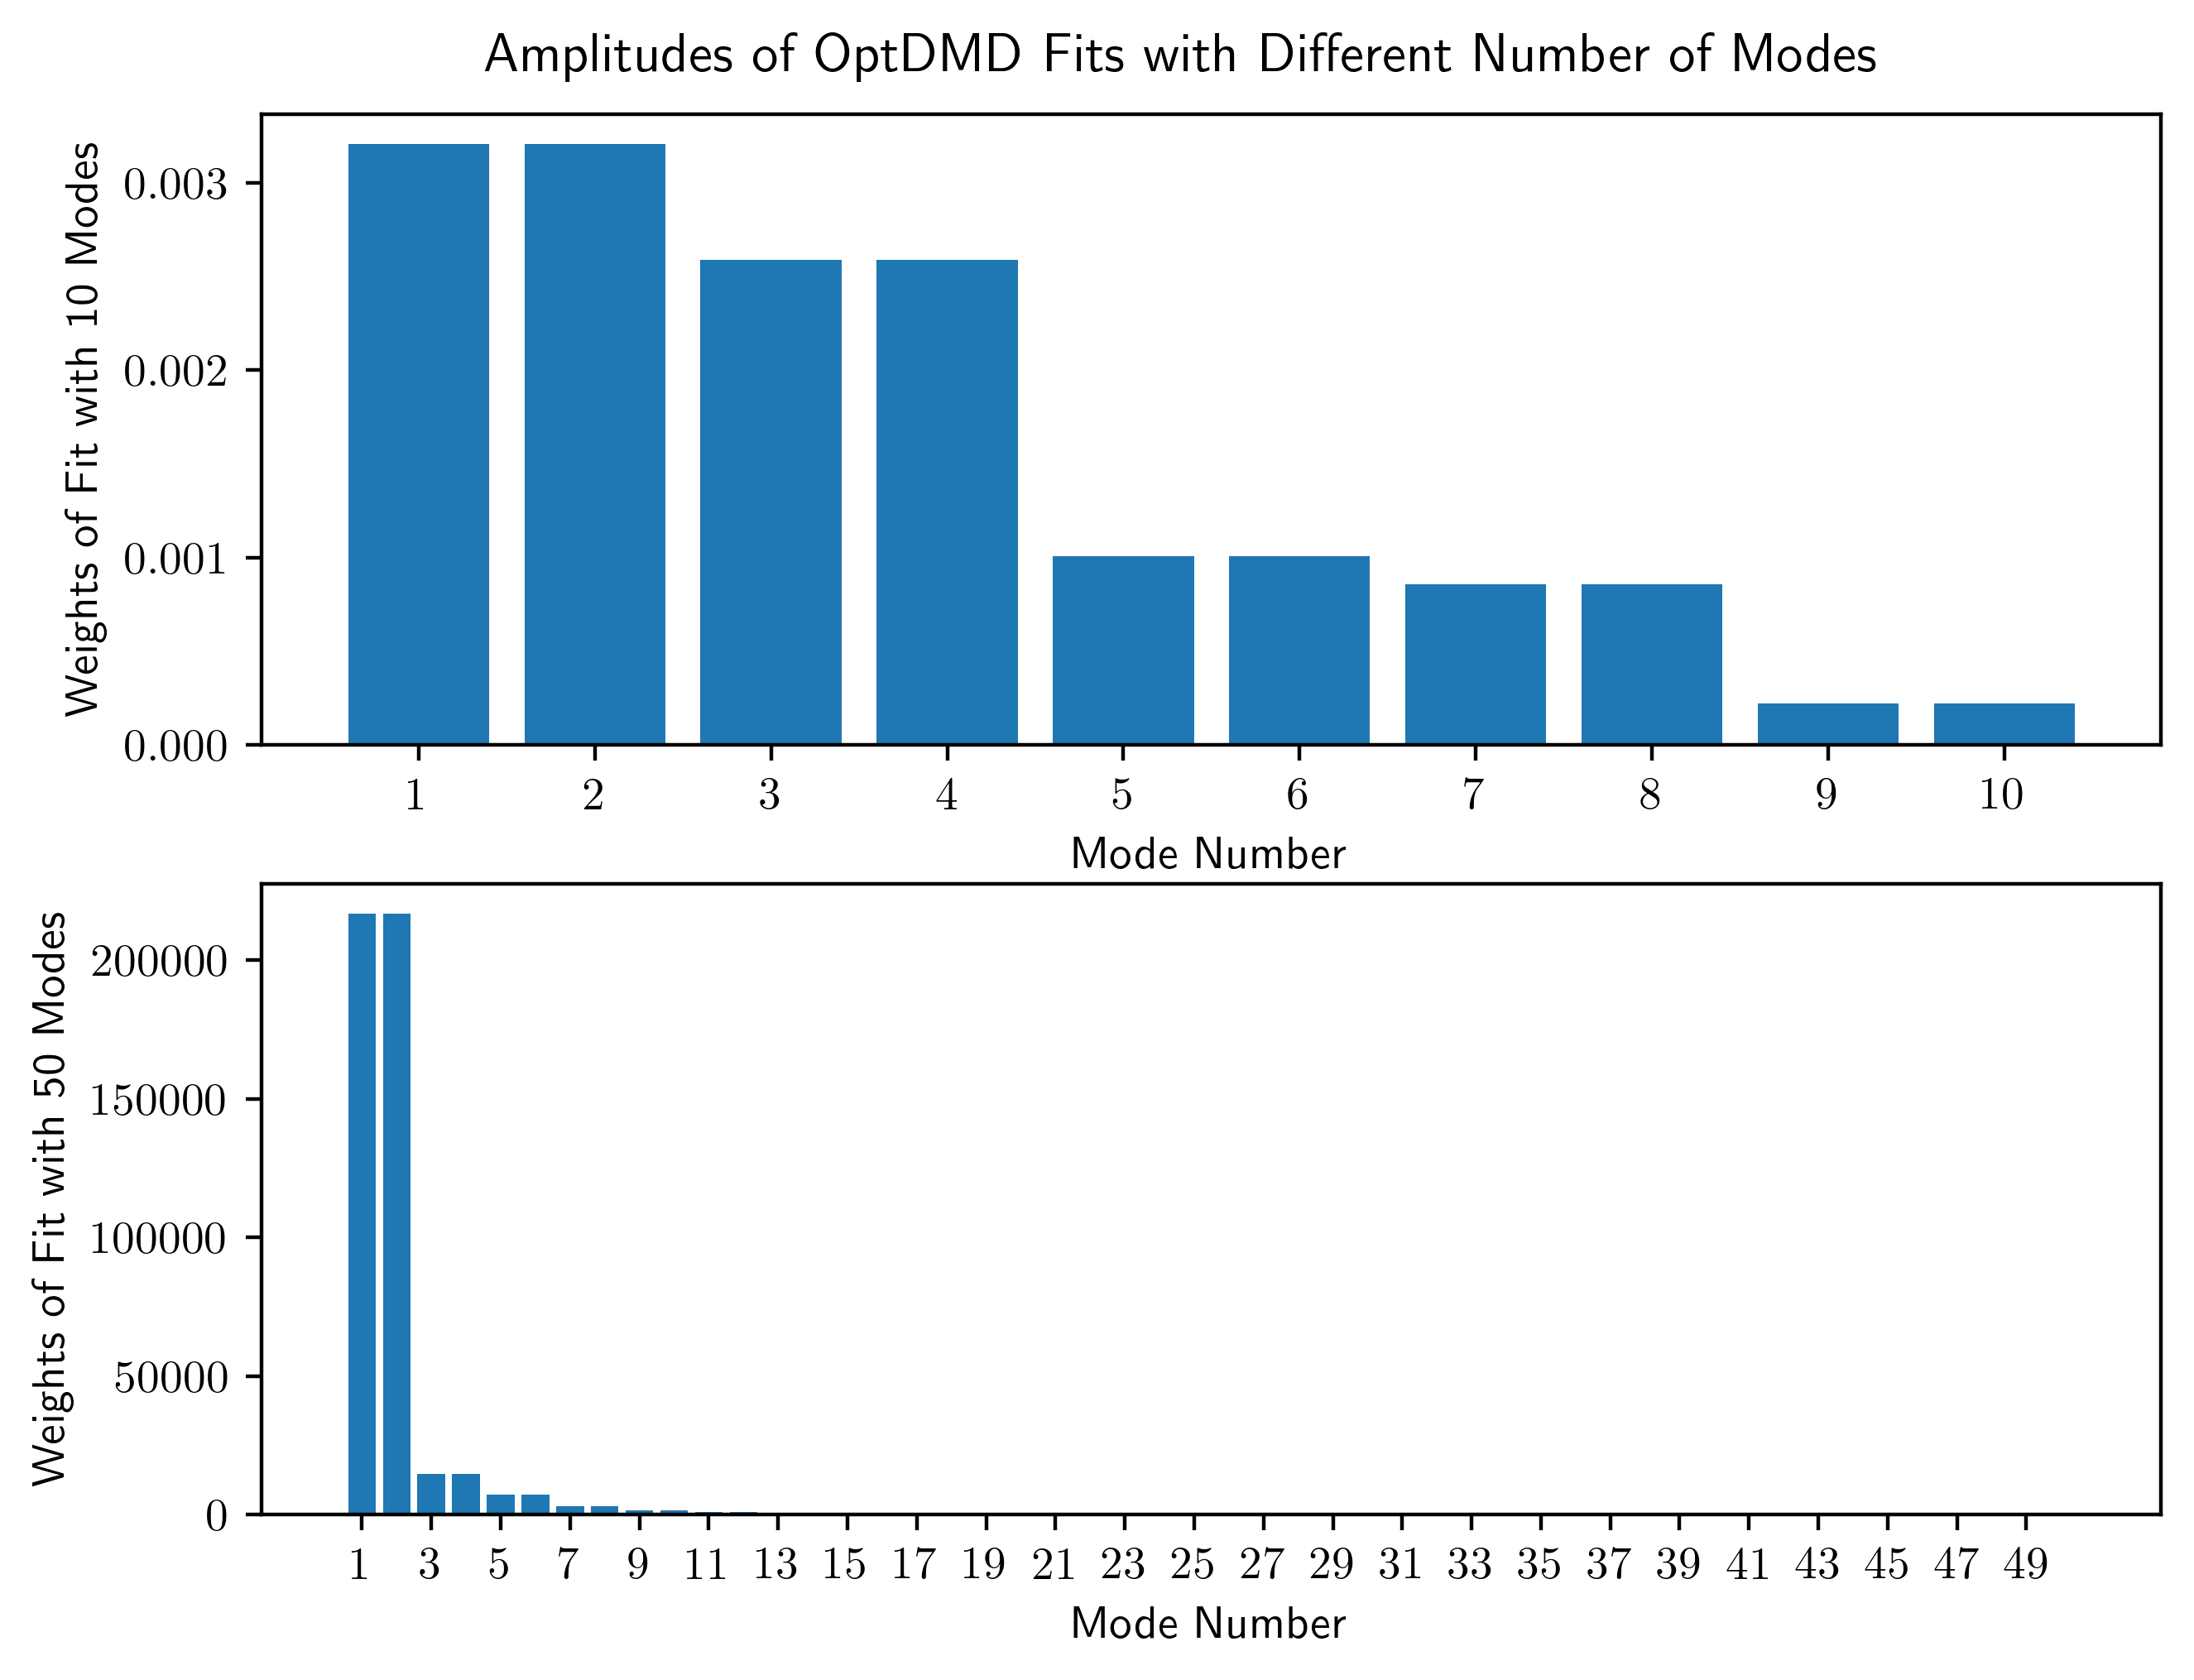

In [10]:
fig, ax = plt.subplots(2,1)
fig.tight_layout()
idx10 = np.argsort(optdmd10.amplitudes)[::-1]
idx50 = np.argsort(optdmd50.amplitudes)[::-1]
ax[0].bar(np.arange(1,11),optdmd10.amplitudes[idx10])
ax[0].set_ylabel("Weights of Fit with 10 Modes")
ax[0].set_xlabel("Mode Number")
ax[0].set_xticks(np.arange(1,11))
ax[1].bar(np.arange(1,51),optdmd50.amplitudes[idx50])
ax[1].set_ylabel("Weights of Fit with 50 Modes")
ax[1].set_xlabel("Mode Number")
ax[1].set_xticks(np.arange(1,51,2))
fig.suptitle("Amplitudes of OptDMD Fits with Different Number of Modes",y=1.01)

It is clear that, especially in the 50 mode case, most of the modes contribute relatively little if anything. As a more rigorous way to determine the correct number of modes, we can compute the optimal hard threshold for the SVD with the formula in the paper here: https://arxiv.org/pdf/1305.5870.pdf. For a $50\times 500$ matrix with unknown noise, the procedure is to discard singular values $\sigma$ smaller than $1.6089\sigma_{median}.$ We will compute the number of singular values above threshold for 10 different $500$ timestep windows.

In [12]:
svs_above_threshold = np.zeros(10)
for i in range(10):
    pca = PCA(n_components=50).fit(SV_normalized[:50,i*500:(i+1)*500])
    svs_above_threshold[i] = np.sum(pca.explained_variance_>1.6089*np.median(pca.explained_variance_))
print("Number of Singular Values above Hard Threshold: " + str(np.mean(svs_above_threshold)))

Number of Singular Values above Hard Threshold: 22.5


Rounding up, we get that the number of singular values above threshold is about 23. The way to interpret the number $23$ here is that singular values $24-50$ contribute more noise than signal to the reconstruction (at least in the limit that our matrix dimensions become very large), and therefore we should truncate at 23. That isn't to say that we need exactly $23$ modes to get a good approximation of our data, but that including modes $24-50$ (asymptotically) does not improve our reconstruction.

Although I am not sure how rigorous it is, applying the same formula to the amplitudes produces a very similar result:

In [14]:
amps_above_threshold = np.zeros(10)
for i in range(10):
    optdmd50_i = BOPDMD(svd_rank=50)
    optdmd50_i.fit(SV_normalized[:50,i*500:(i+1)*500],np.arange(500))
    amps_above_threshold[i] = np.sum(optdmd50_i.amplitudes > np.median(optdmd50_i.amplitudes)*1.6089)
print("Number of Amplitudes above Hard Threshold: " + str(np.mean(amps_above_threshold)))

Number of Amplitudes above Hard Threshold: 23.2


Let's do a 24 mode fit.

In [15]:
optdmd24 = BOPDMD(svd_rank=24,num_trials=0)
optdmd24.fit(SV_normalized[:50,:500],np.arange(500));

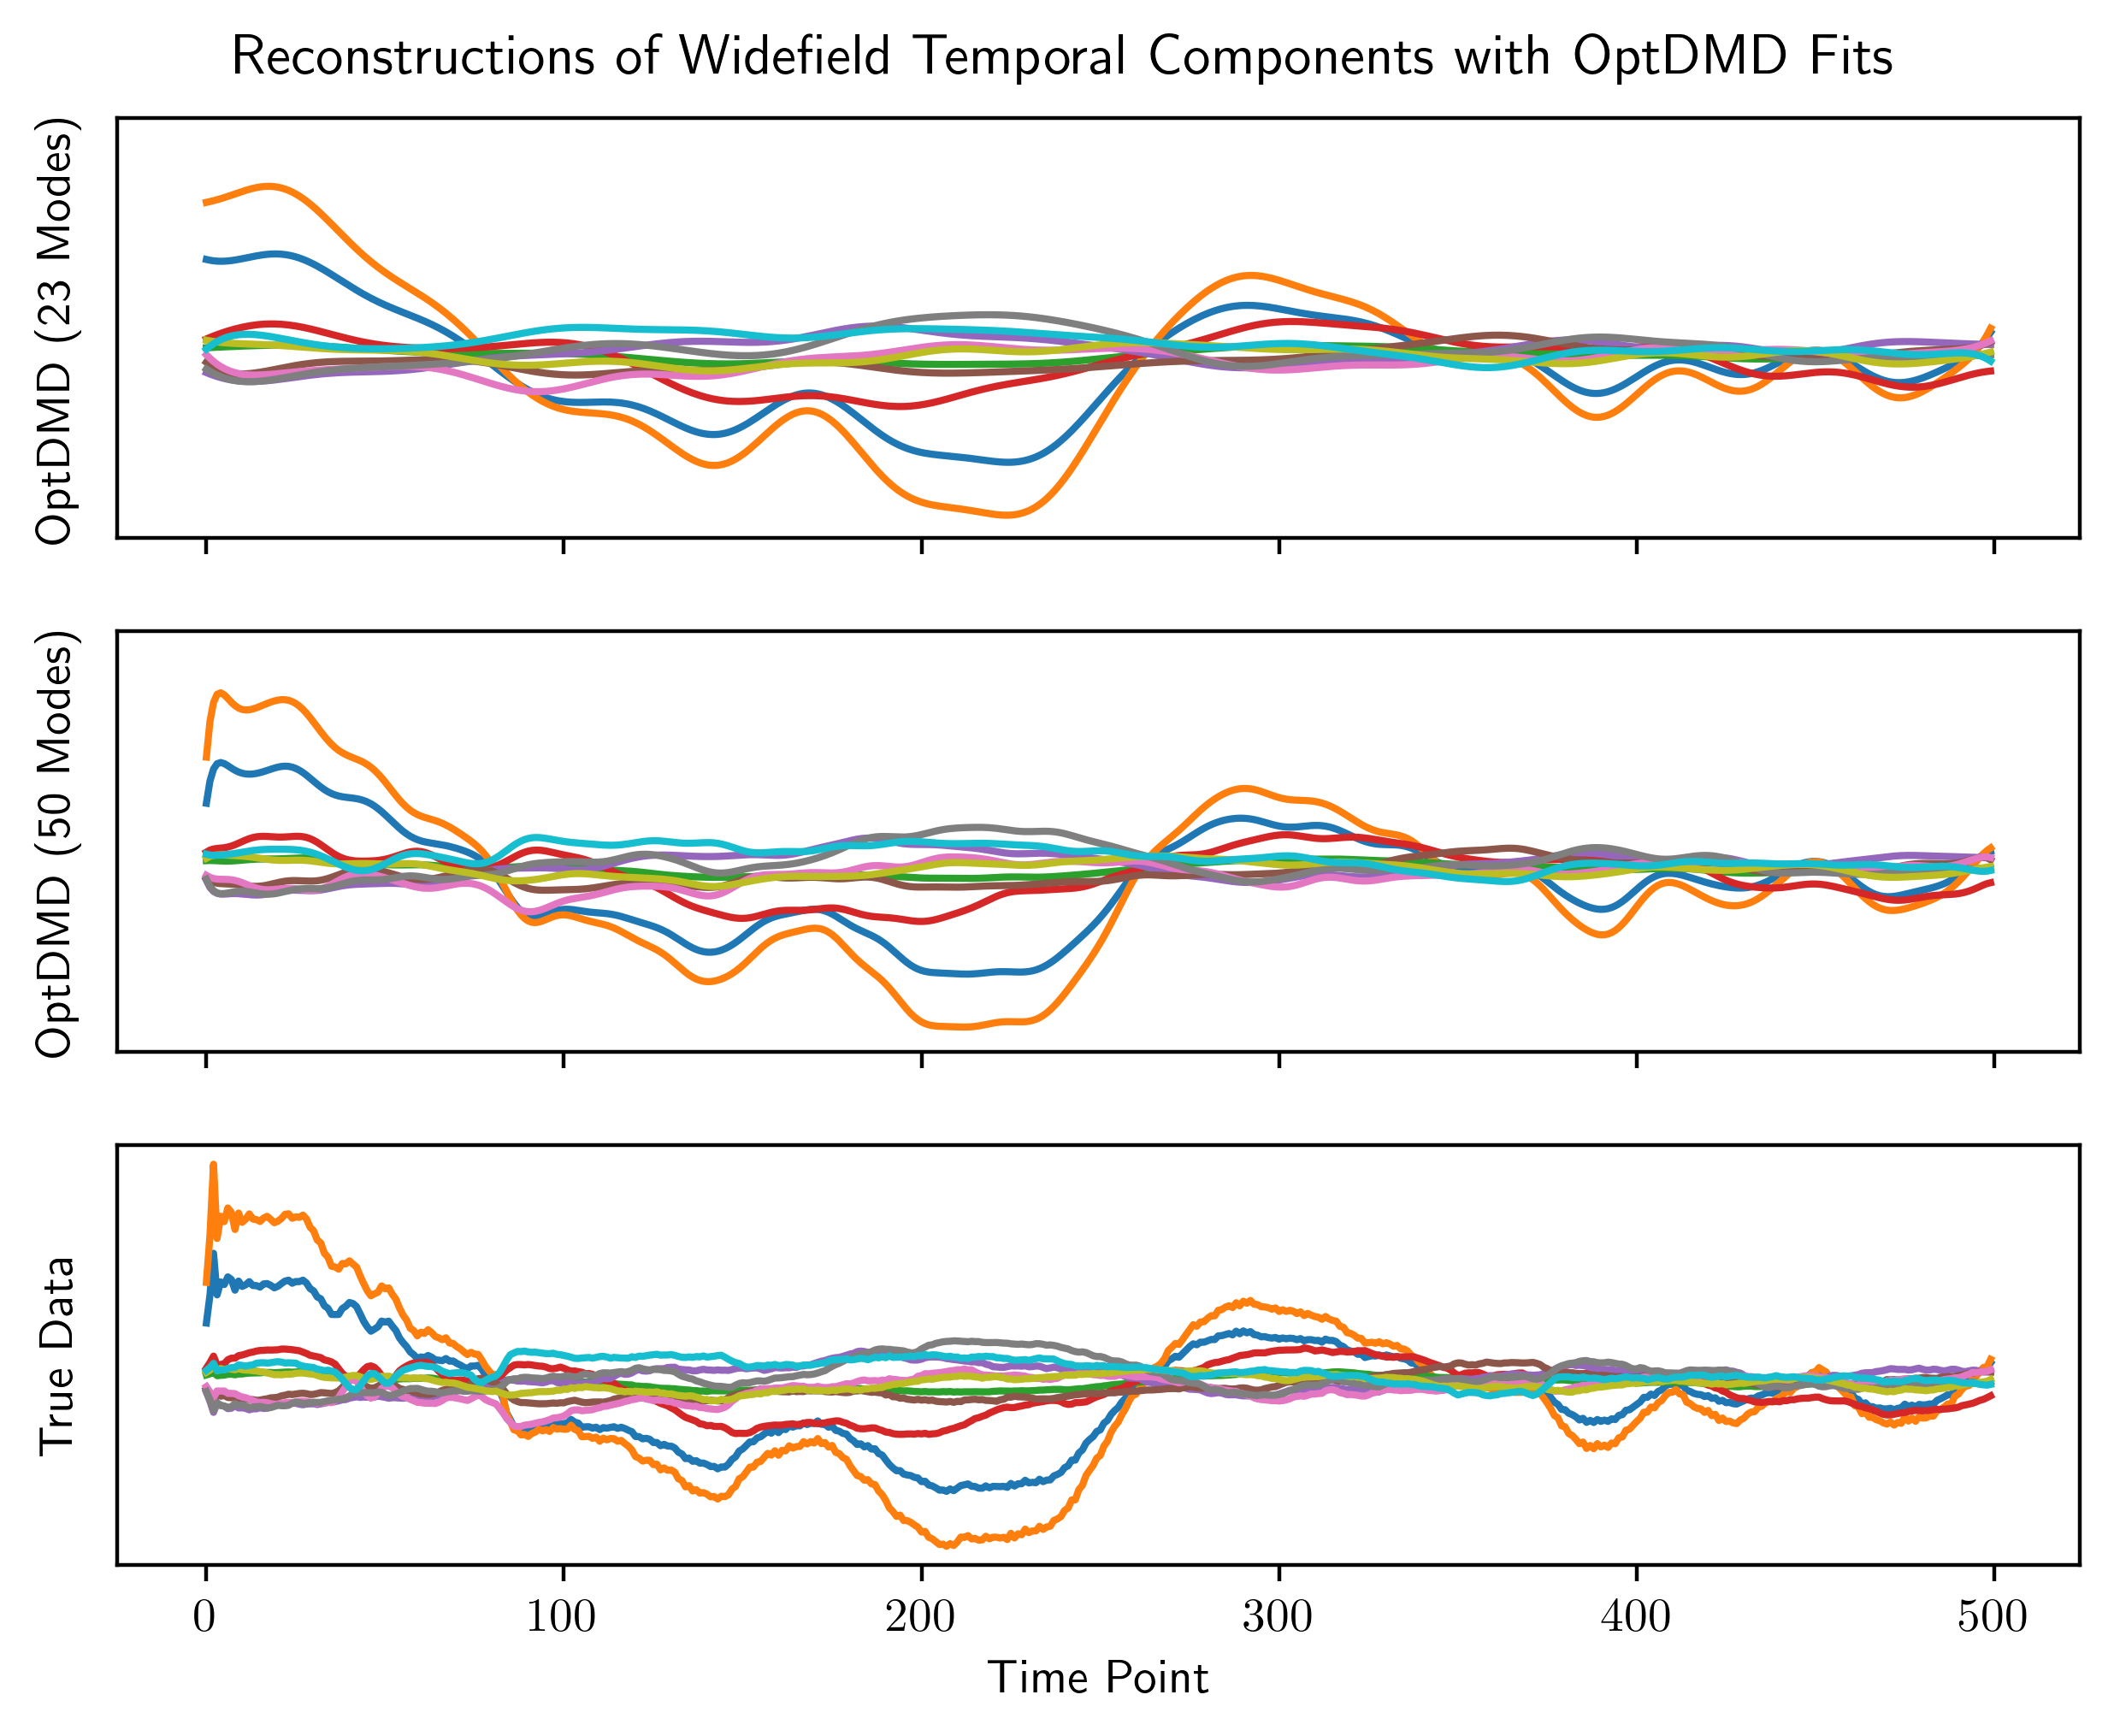

In [16]:
fig,ax = plt.subplots(3,1,sharex=True,sharey=True)
fig.tight_layout()
for i in range(10):
    ax[0].plot(np.real(optdmd24.reconstructed_data[i,:]))
    ax[0].set_ylabel("OptDMD (23 Modes)")
    ax[0].set_yticks([])
    ax[1].plot(np.real(optdmd50.reconstructed_data[i,:]))
    ax[1].set_ylabel("OptDMD (50 Modes)")
    ax[1].set_yticks([])
    ax[2].plot(np.real(SV_normalized[i,:500]))
    ax[2].set_ylabel("True Data")
    ax[2].set_yticks([])
ax[2].set_xlabel("Time Point");
fig.suptitle("Reconstructions of Widefield Temporal Components with OptDMD Fits",y=1.01);

In [17]:
print("10 mode RSE: " + str(RSE(optdmd10.reconstructed_data,SV_normalized[:50,:500])))
print("24 mode RSE: " + str(RSE(optdmd24.reconstructed_data,SV_normalized[:50,:500])))
print("50 mode RSE: " + str(RSE(optdmd50.reconstructed_data,SV_normalized[:50,:500])))

10 mode RSE: 0.05405660102131771
24 mode RSE: 0.011769213679550217
50 mode RSE: 0.004564296174925763


So we see that the $24$ mode fit is a little more than $3$x more accurate than the $10$ mode fit, while the $50$ mode fit is a little more than $3$x better than the $24$ mode fit. In terms of what these metrics say, the $10$ mode fit is nearly $9$x better at predicting the training data than guessing that the data equals its average value at each point, while the $50$ mode fit is about $84$x better. We can visualize more information about these fits with pyDMD's plotter function. This plots the variance captured by each singular value from the data, the eigenvalues in discrete-time, the eigenvalues in continuous time (scaled in size in proportion to their amplitudes), the top three modes (ranked by amplitude), and their dynamics (the time evolution of the associated exponential $e^{\lambda_jt}$).

First let's look at the plot summary for OptDMD with 10 modes.

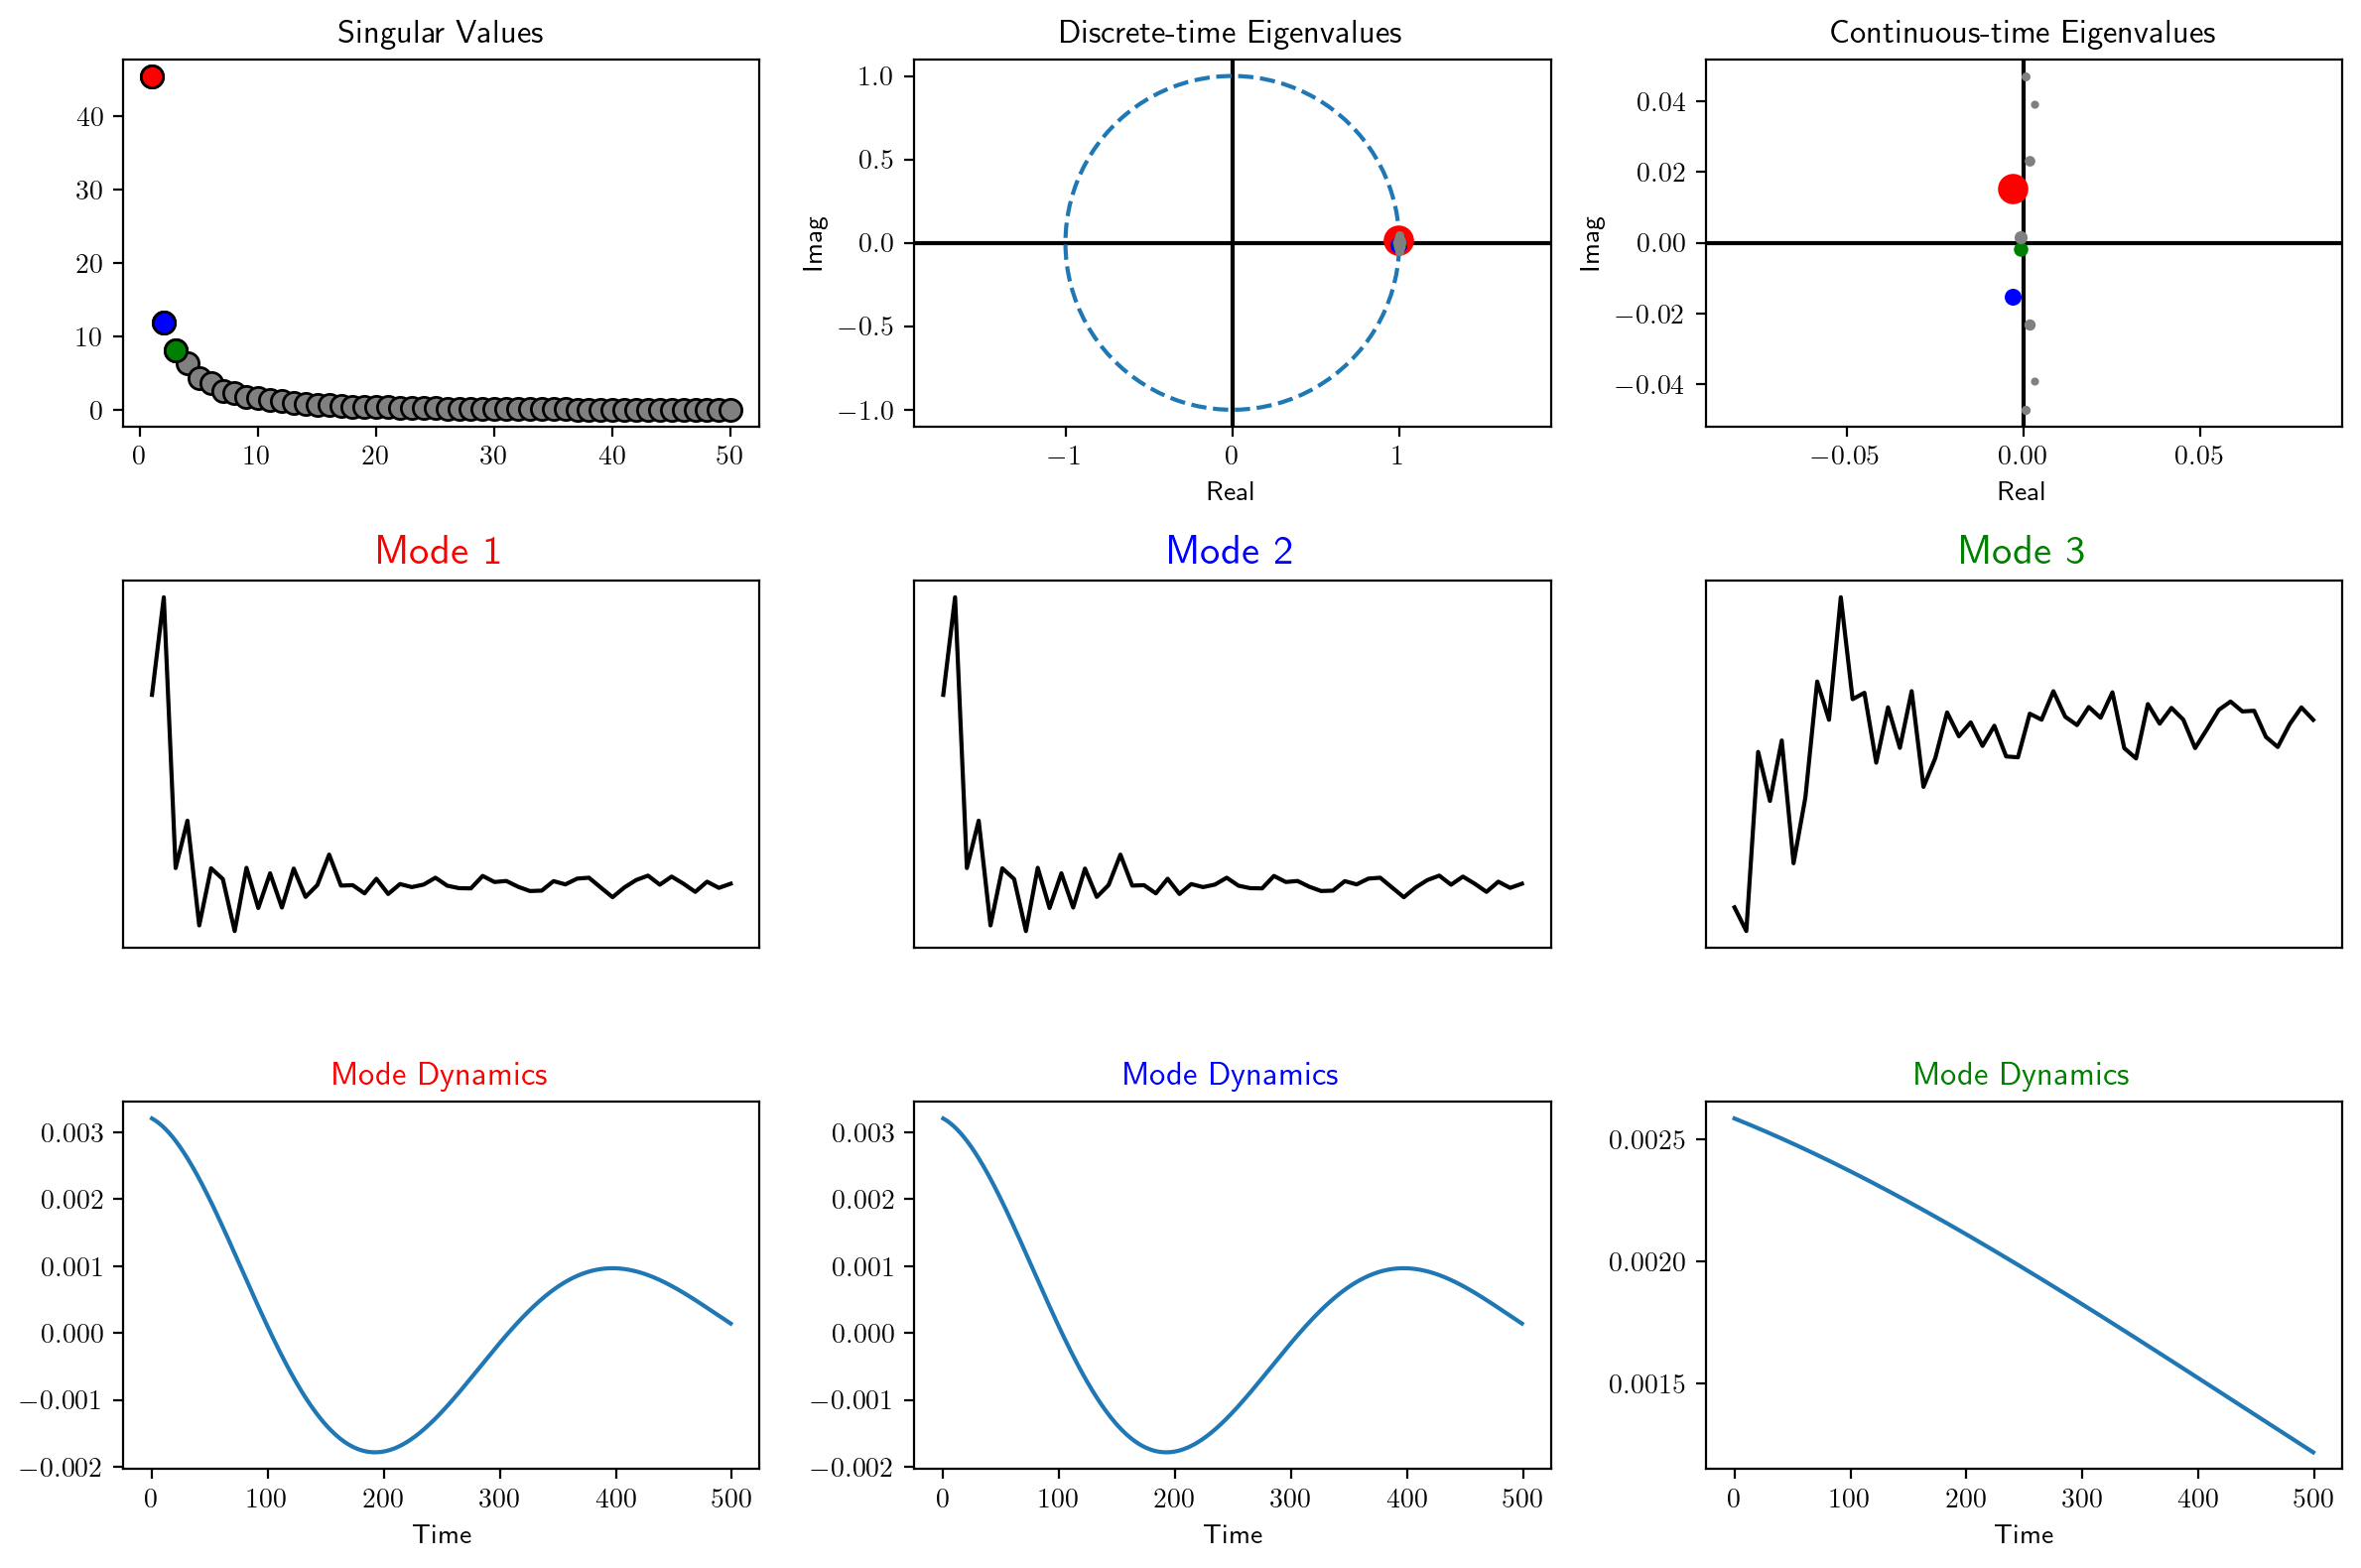

In [18]:
plotter.plot_summary(optdmd10)

Next for the $24$ mode fit.

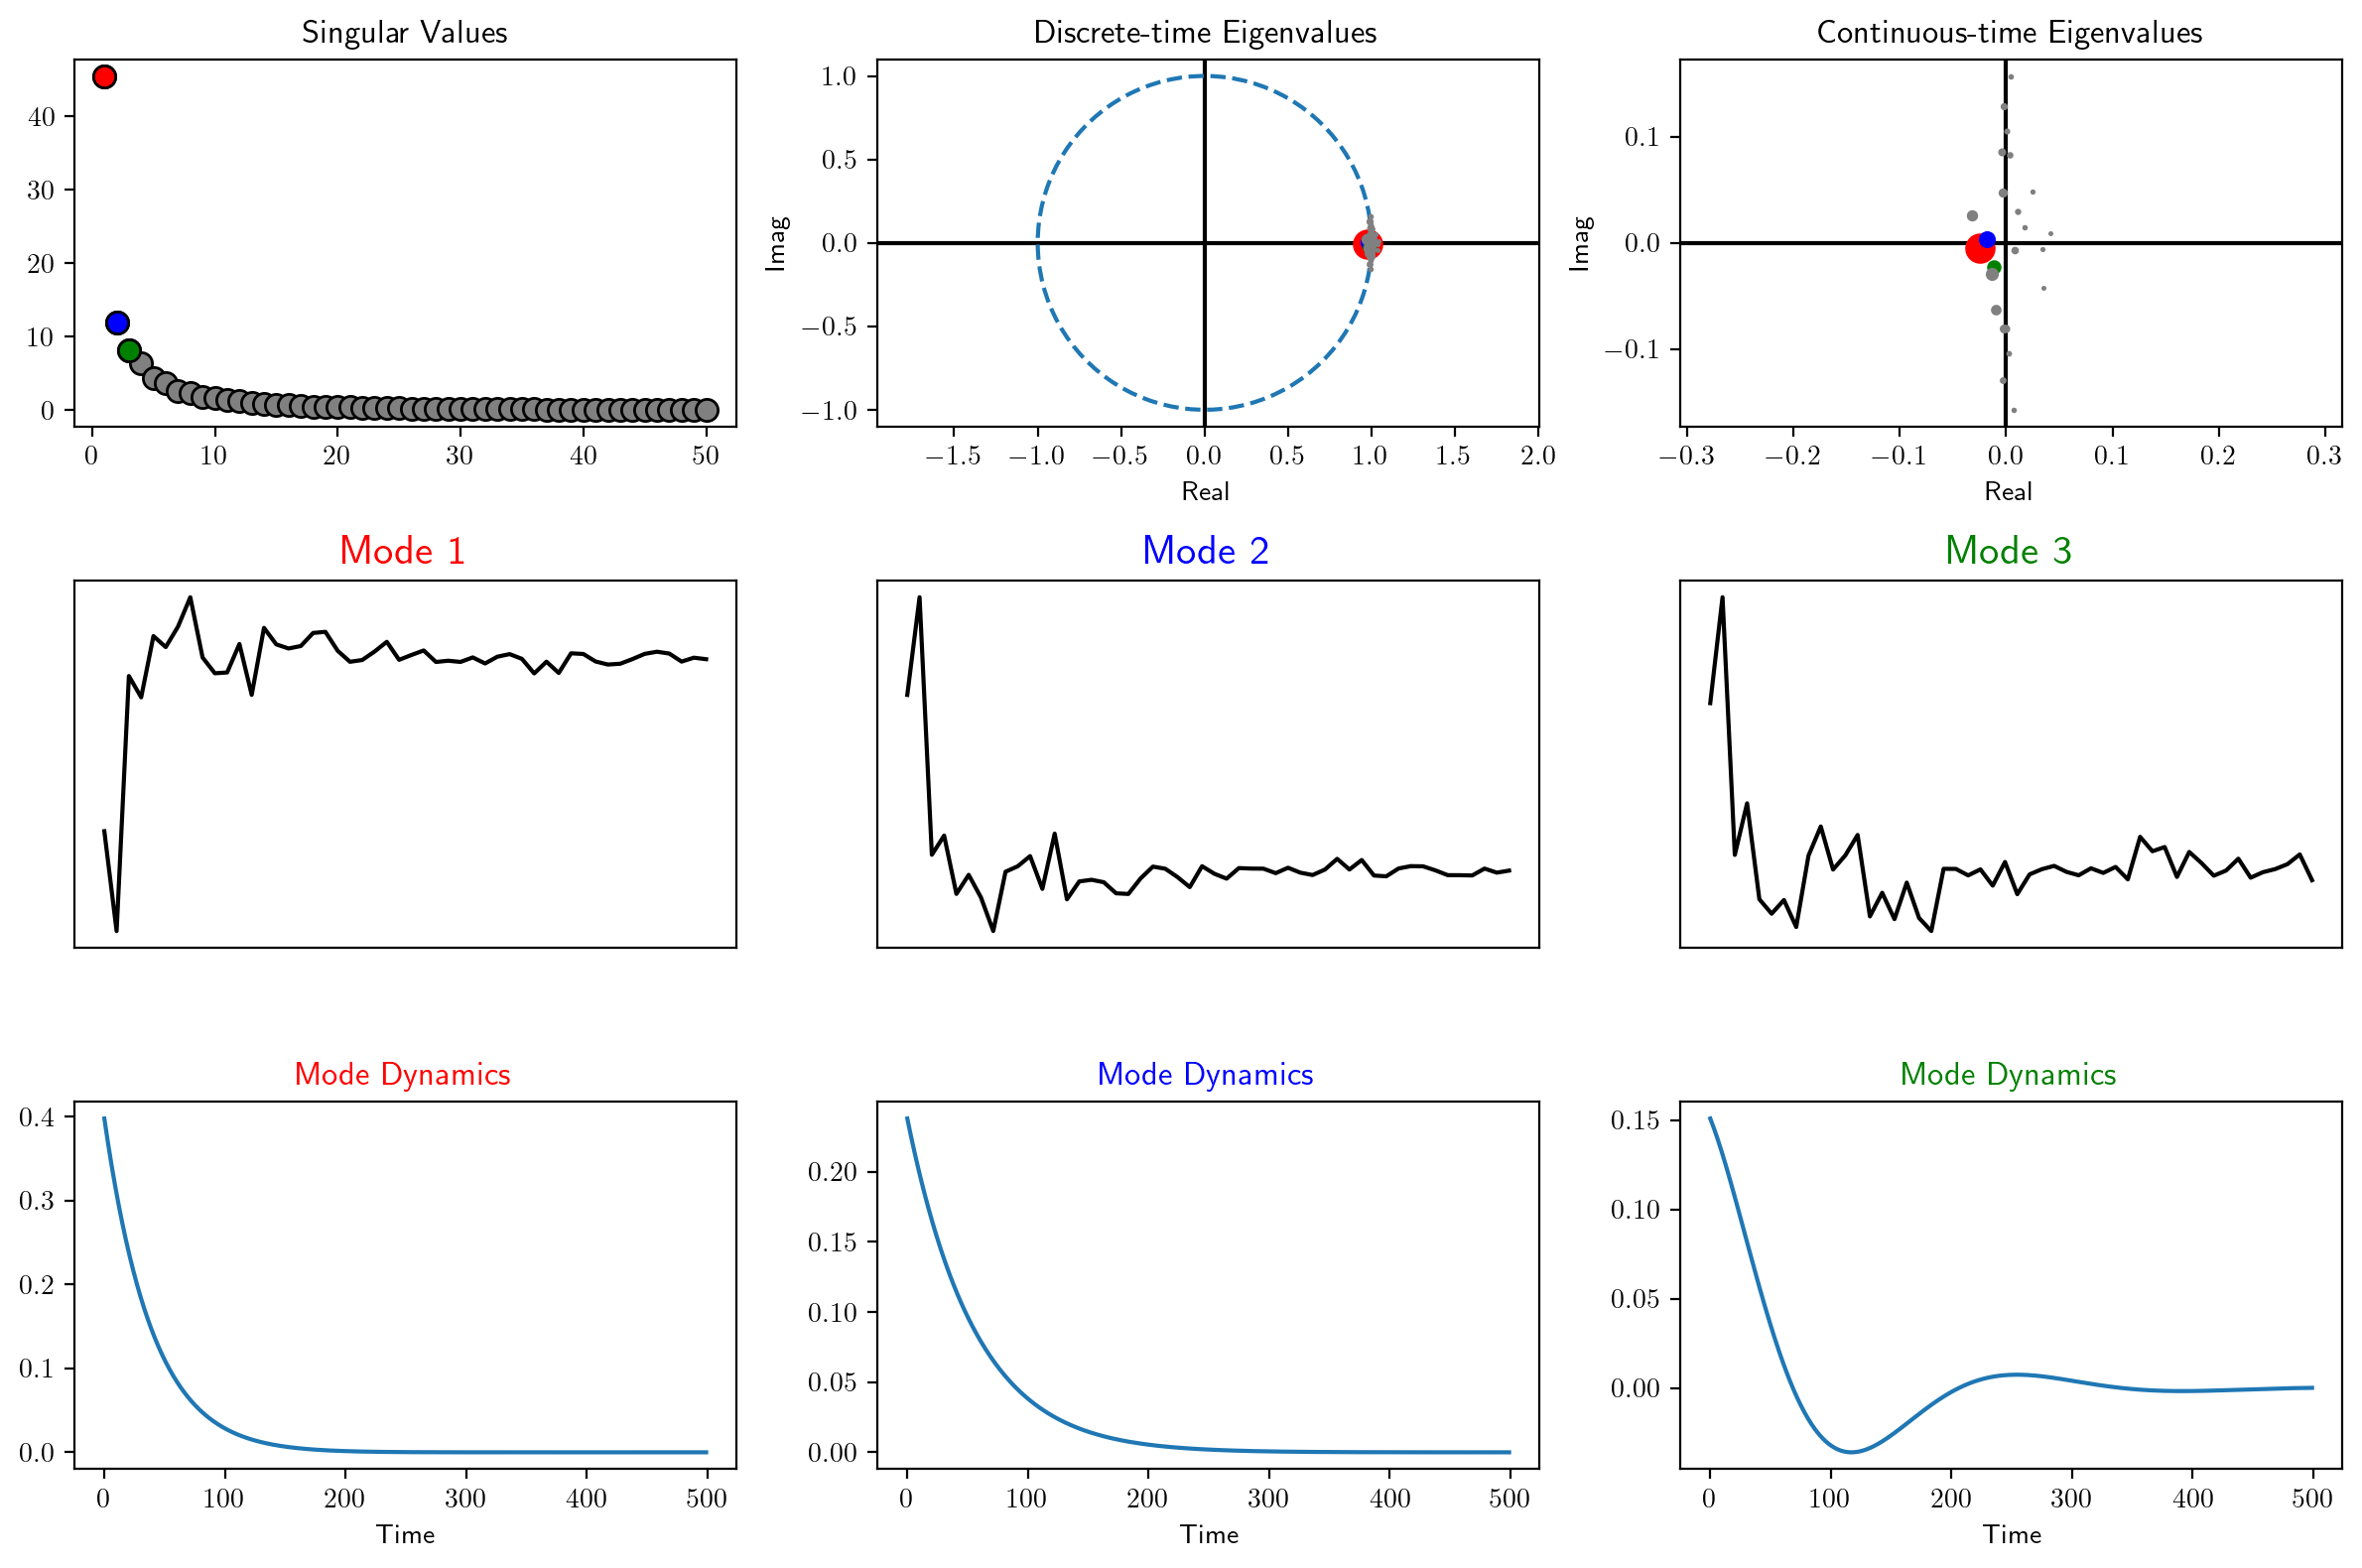

In [19]:
plotter.plot_summary(optdmd24)

Finally for the $50$ mode fit.

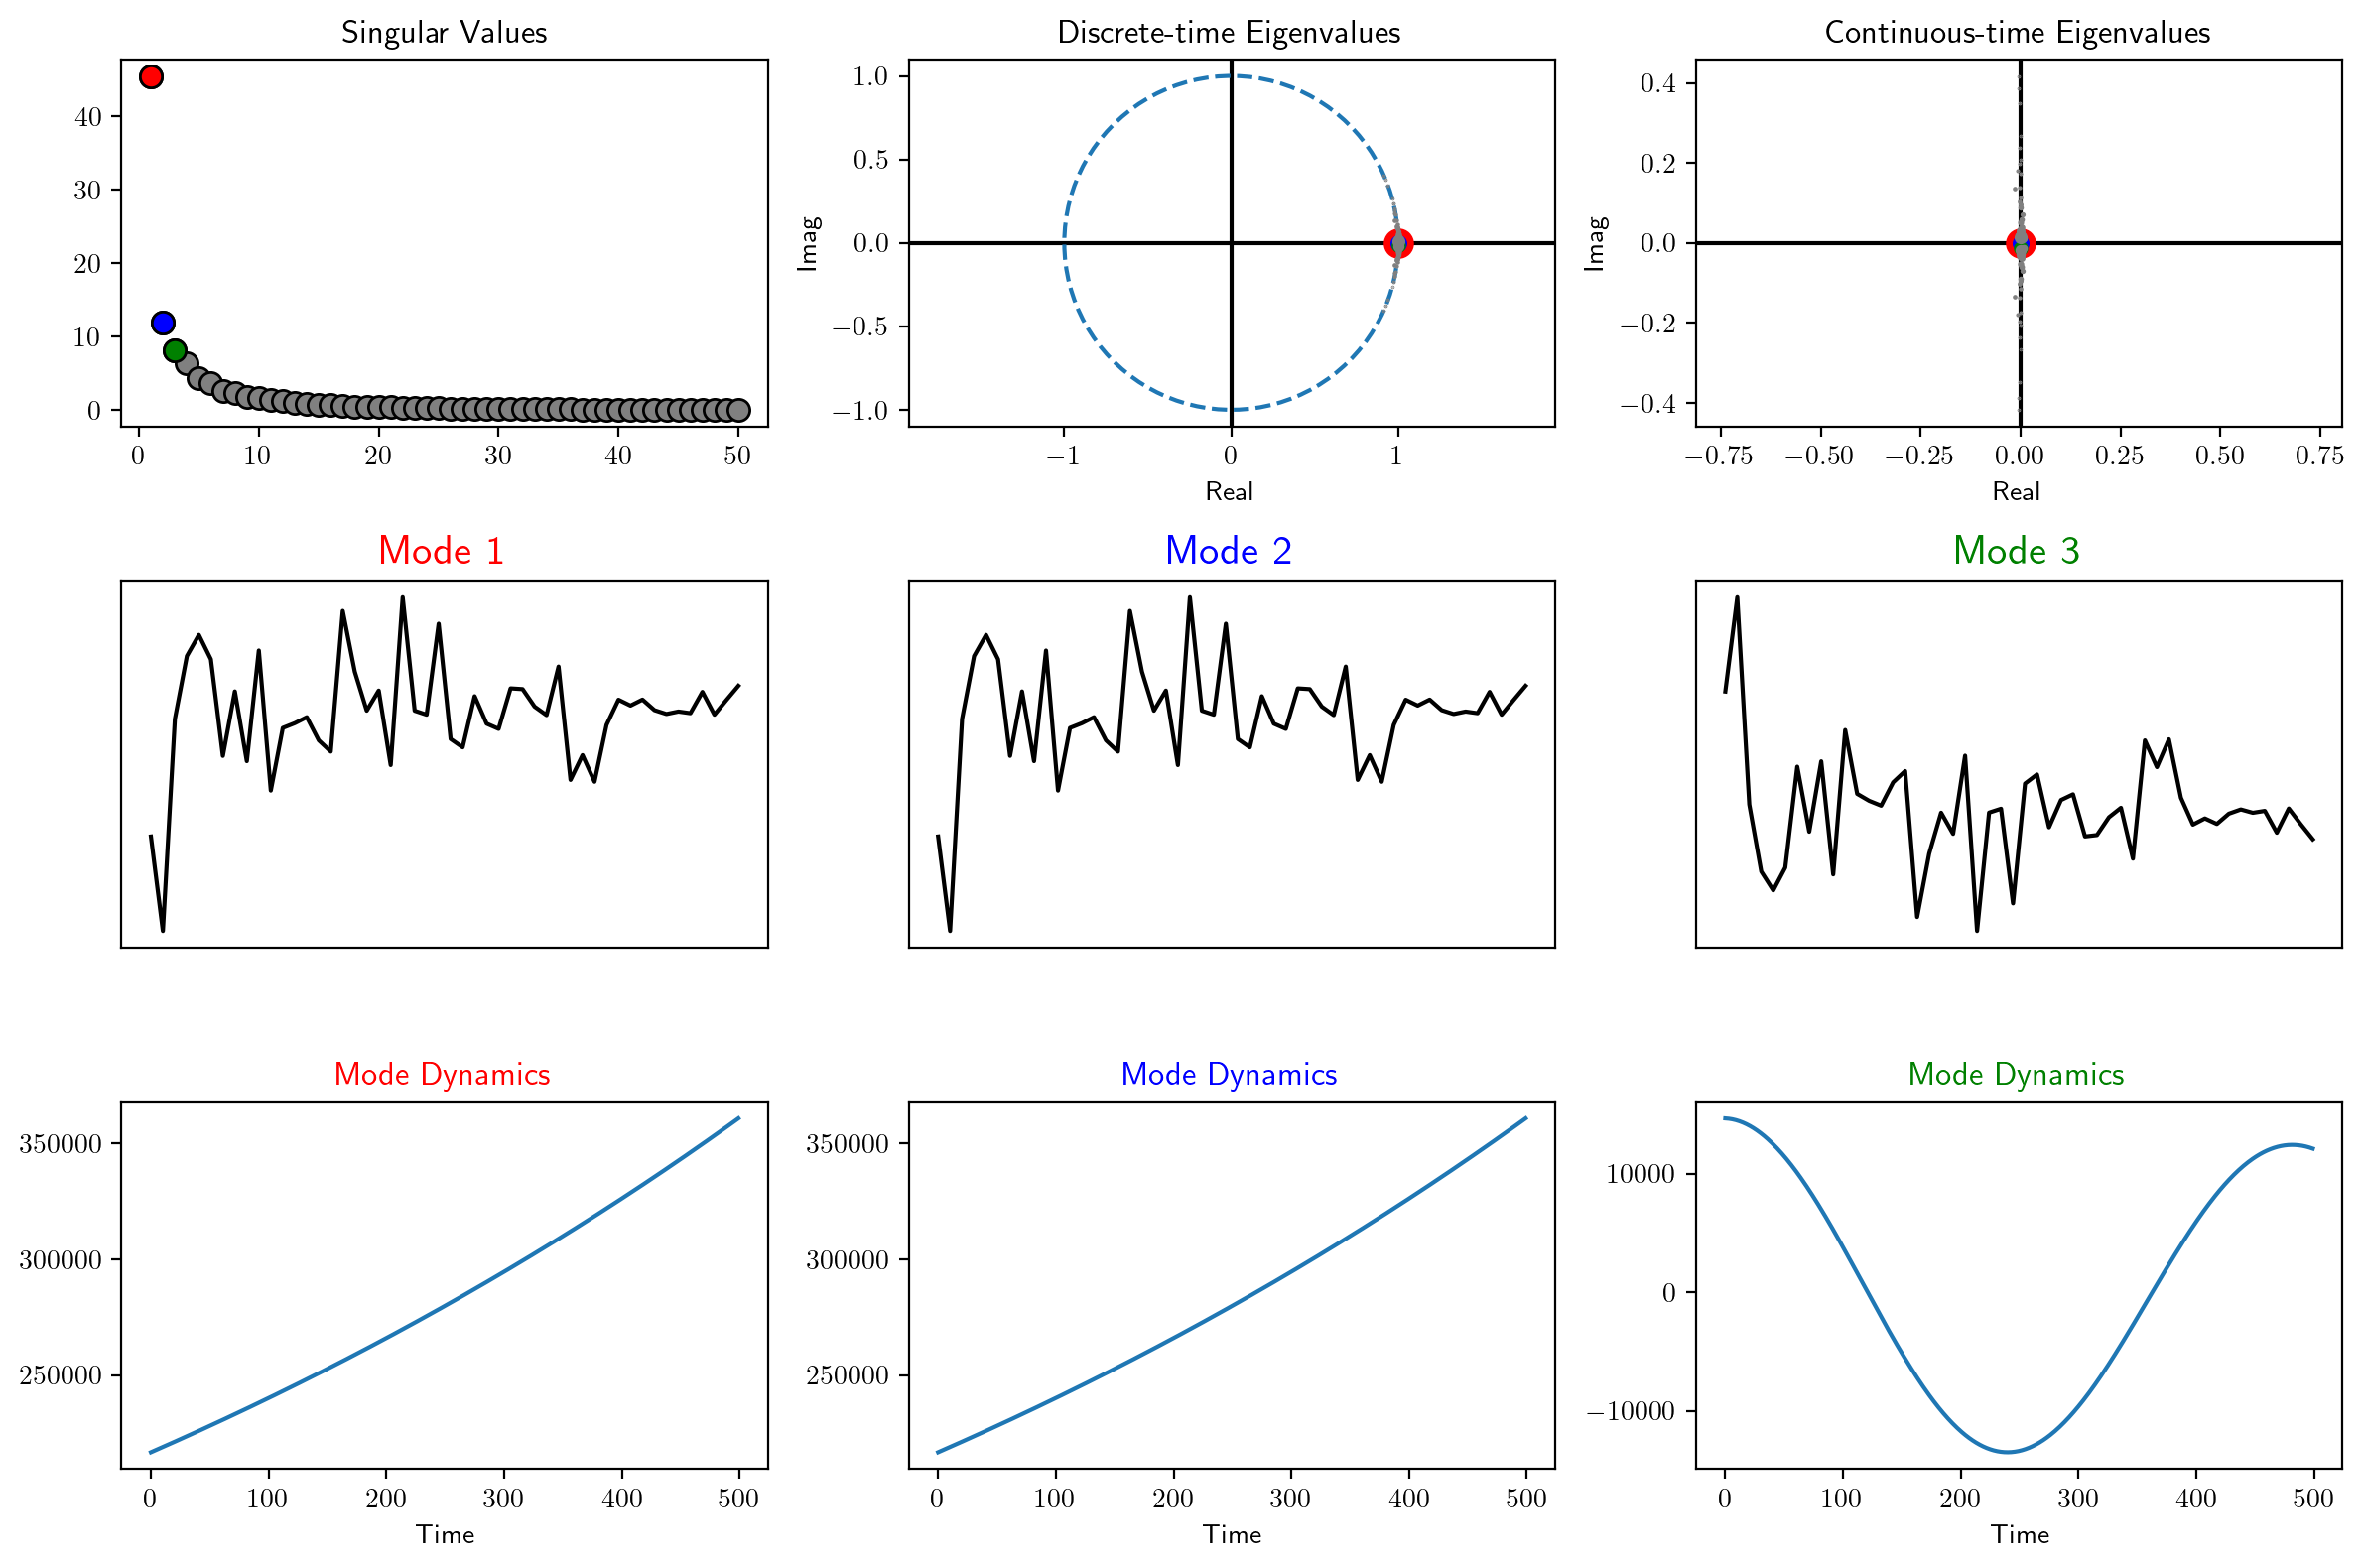

In [20]:
plotter.plot_summary(optdmd50)

Notice that not all of the OptDMD eigenvalues lie to the left of the imaginary axis. This explains why the OptDMD reconstruction does not decay to zero (and in fact will diverge to infinity for times beyond the training data).

With the OptDMD fits, some of the eigenvalues lie to the left of the imaginary axis and some lie to the right. Thus, as some of the modes decay, others rise to take their place. This also explains why OptDMD works better out of the box as a modal decomposition of data rather than as a data forecaster. The modes with eigenvalues that have positive real part will continue to grow exponentially beyond the training period, while the modes with eigenvalues with negative real part will simply decay to zero, and thus will not counteract the growing modes.

Let's look at the frequencies found in each case, first for the 10 mode case. Note that we do not take a logarithm of the frequencies in this case, as pyDMD's BOPDMD method returns the eigenvalues in continuous time.

In [21]:
df = pd.DataFrame()
dt = 0.0285
optdmd_freqs = np.abs(np.imag(optdmd10.eigs)) / (2*np.pi*dt)
optdmd_amplitudes = np.abs(optdmd10.amplitudes)
idx = np.argsort(optdmd10.amplitudes)[::-1]
df['Frequencies'] = optdmd_freqs[idx]
df['Amplitudes'] = optdmd_amplitudes[idx]
print(df)

   Frequencies  Amplitudes
0     0.085684    0.003206
1     0.085684    0.003206
2     0.009194    0.002587
3     0.009194    0.002587
4     0.129065    0.001010
5     0.129065    0.001010
6     0.263649    0.000857
7     0.263649    0.000857
8     0.218623    0.000225
9     0.218623    0.000225


Next let's look at the 24 mode case.

In [22]:
df = pd.DataFrame()
dt = 0.0285
optdmd_freqs = np.abs(np.imag(optdmd24.eigs)) / (2*np.pi*dt)
optdmd_amplitudes = np.abs(optdmd24.amplitudes)
idx = np.argsort(optdmd24.amplitudes)[::-1]
df['Frequencies'] = optdmd_freqs[idx]
df['Amplitudes'] = optdmd_amplitudes[idx]
print(df)

    Frequencies    Amplitudes
0      0.028097  3.977641e-01
1      0.018087  2.378027e-01
2      0.127898  1.508808e-01
3      0.165532  1.216704e-01
4      0.143707  7.346711e-02
5      0.351836  6.019770e-03
6      0.262052  3.542620e-03
7      0.450912  3.018932e-03
8      0.449243  1.768634e-03
9      0.475556  1.243305e-03
10     0.037255  7.462575e-04
11     0.718950  5.261613e-04
12     0.718313  4.375907e-04
13     0.460837  2.369867e-04
14     0.162818  1.852500e-04
15     0.588778  1.252361e-04
16     0.582169  1.014670e-04
17     0.876616  5.524983e-05
18     0.080694  4.319395e-05
19     0.876696  1.753322e-05
20     0.267922  1.478436e-07
21     0.031462  2.166783e-08
22     0.236412  7.465513e-10
23     0.050173  4.061877e-10


Finally let's look at the 50 mode case.

In [23]:
df = pd.DataFrame()
dt = 0.0285
optdmd_freqs = np.abs(np.imag(optdmd50.eigs)) / (2*np.pi*dt)
optdmd_amplitudes = np.abs(optdmd50.amplitudes)
idx = np.argsort(optdmd50.amplitudes)[::-1]
df['Frequencies'] = optdmd_freqs[idx]
df['Amplitudes'] = optdmd_amplitudes[idx]
print(df)

    Frequencies     Amplitudes
0      0.000887  216708.100303
1      0.000887  216708.099794
2      0.072561   14644.946904
3      0.072561   14644.944159
4      0.106411    7252.141591
5      0.106411    7252.139586
6      0.155900    3147.556096
7      0.155900    3147.554845
8      0.181194    1712.616371
9      0.181194    1712.615581
10     0.066221    1033.998381
11     0.066221    1033.998183
12     0.216889     279.092282
13     0.216889     279.092130
14     0.288985      32.202281
15     0.288985      32.202258
16     0.332503       5.103741
17     0.332503       5.103737
18     0.498209       0.467683
19     0.498209       0.467683
20     0.393420       0.434367
21     0.393420       0.434366
22     0.533689       0.282142
23     0.533689       0.282142
24     0.572945       0.230878
25     0.572945       0.230878
26     0.753087       0.024100
27     0.753087       0.024100
28     0.636533       0.013354
29     0.636533       0.013354
30     0.767678       0.001948
31     0

Let's focus on understanding the 10 mode case, as with only ten modes we can reasonably analyze each mode. We will reconstruct the data from each individual mode.

In [24]:
modes = np.zeros((50,500,10),dtype='complex128')
t = np.arange(1,501)
for i in range(10):
    # Replace amplitudes with 1 to get unscaled modes
    modes[:,:,i] = np.linalg.multi_dot(
                   [optdmd10.modes[:,i][np.newaxis].T,np.array([[optdmd10.amplitudes[i]]]),np.exp(np.outer(optdmd10.eigs[i][np.newaxis],t))])

Next, let's multiply back $U$ and $\Sigma$ to make the modes more interpretable in the $10$ mode case. First we'll load the spatial data and construct the first true frame.

In [40]:
# Load widefield spatial data
# This data is 560x560x2000, where the first two dimensions are pixels
# and the last dimension is SVD mode. We will keep only the top 50 modes
wf_spat = np.load('../Mouse Data/svdSpatialComponents.npy')
top50 = wf_spat[:,:,:50].copy()

# Set aside memory for all matrix multiplications we will do
matmul_out = np.empty((560,560))

# Compute first frame
USV = np.matmul(top50,SV_norm[0]*SV_normalized[:50,0],out=matmul_out)
# Delete wf_spat from memory
del wf_spat

We will create an animation showing the true data, the reconstruction, and the top ten modes. 

The setup is as follows. Given an SVD of our widefield data $X=U\Sigma V^T$, we have used OptDMD to obtain an approximation

$$V^T[:,i]\approx\sum_{j=1}^n b_j\phi_j e^{\lambda_jt_i}.$$

To reconstruct our original data, we compute
$$U\Sigma V^T[:,i]\approx U\Sigma \sum_{j=1}^n b_j\phi_j e^{\lambda_jt_i}=\sum_{j=1}^n b_j(U\Sigma \phi_j e^{\lambda_j t_i}).$$

Thus, our reconstructed data is a linear combination of the OptDMD dynamics multiplied by $U\Sigma$, with the weights being the amplitudes from the OptDMD fit.

**Note**: I have, at different points, created three videos with this code, 'OptDMD Modes.mp4', and 'OptDMD Modes Colorbar.mp4', and 'OptDMD Modes Colorbar Scaled.mp4'. The code below will create 'OptDMD Modes Colorbar Scaled.mp4.' In 'OptDMD Modes.mp4', the modes evolve with their own color scaling. I do not scale them by their amplitudes. The color scaling also changes in each frame, so that each individual mode's oscillations are clear. In the 'OptDMD Modes Colorbar.mp4', there is a constant scaling used across all videos, but the modes **are not** scaled by their amplitudes. The result is that the modes are on very different scales from the reconstruction, but the reconstruction is the weighted sum of the modes shown with the weights below each video. In 'OptDMD Modes Colorbar Scaled.mp4', all modes, the data, and the reconstruction are on the same scale, and the modes **are scaled by their amplitudes**. Thus the reconstruction video is the sum of the mode videos **with each video weighted equally**.

**Note 2**: This code takes a while (~20 minutes) on my computer to run.

At iteration 0
At iteration 0
At iteration 1
At iteration 2
At iteration 3
At iteration 4
At iteration 5
At iteration 6
At iteration 7
At iteration 8
At iteration 9
At iteration 10
At iteration 11
At iteration 12
At iteration 13
At iteration 14
At iteration 15
At iteration 16
At iteration 17
At iteration 18
At iteration 19
At iteration 20
At iteration 21
At iteration 22
At iteration 23
At iteration 24
At iteration 25
At iteration 26
At iteration 27
At iteration 28
At iteration 29
At iteration 30
At iteration 31
At iteration 32
At iteration 33
At iteration 34
At iteration 35
At iteration 36
At iteration 37
At iteration 38
At iteration 39
At iteration 40
At iteration 41
At iteration 42
At iteration 43
At iteration 44
At iteration 45
At iteration 46
At iteration 47
At iteration 48
At iteration 49
At iteration 50
At iteration 51
At iteration 52
At iteration 53
At iteration 54
At iteration 55
At iteration 56
At iteration 57
At iteration 58
At iteration 59
At iteration 60
At iteration 61
At 

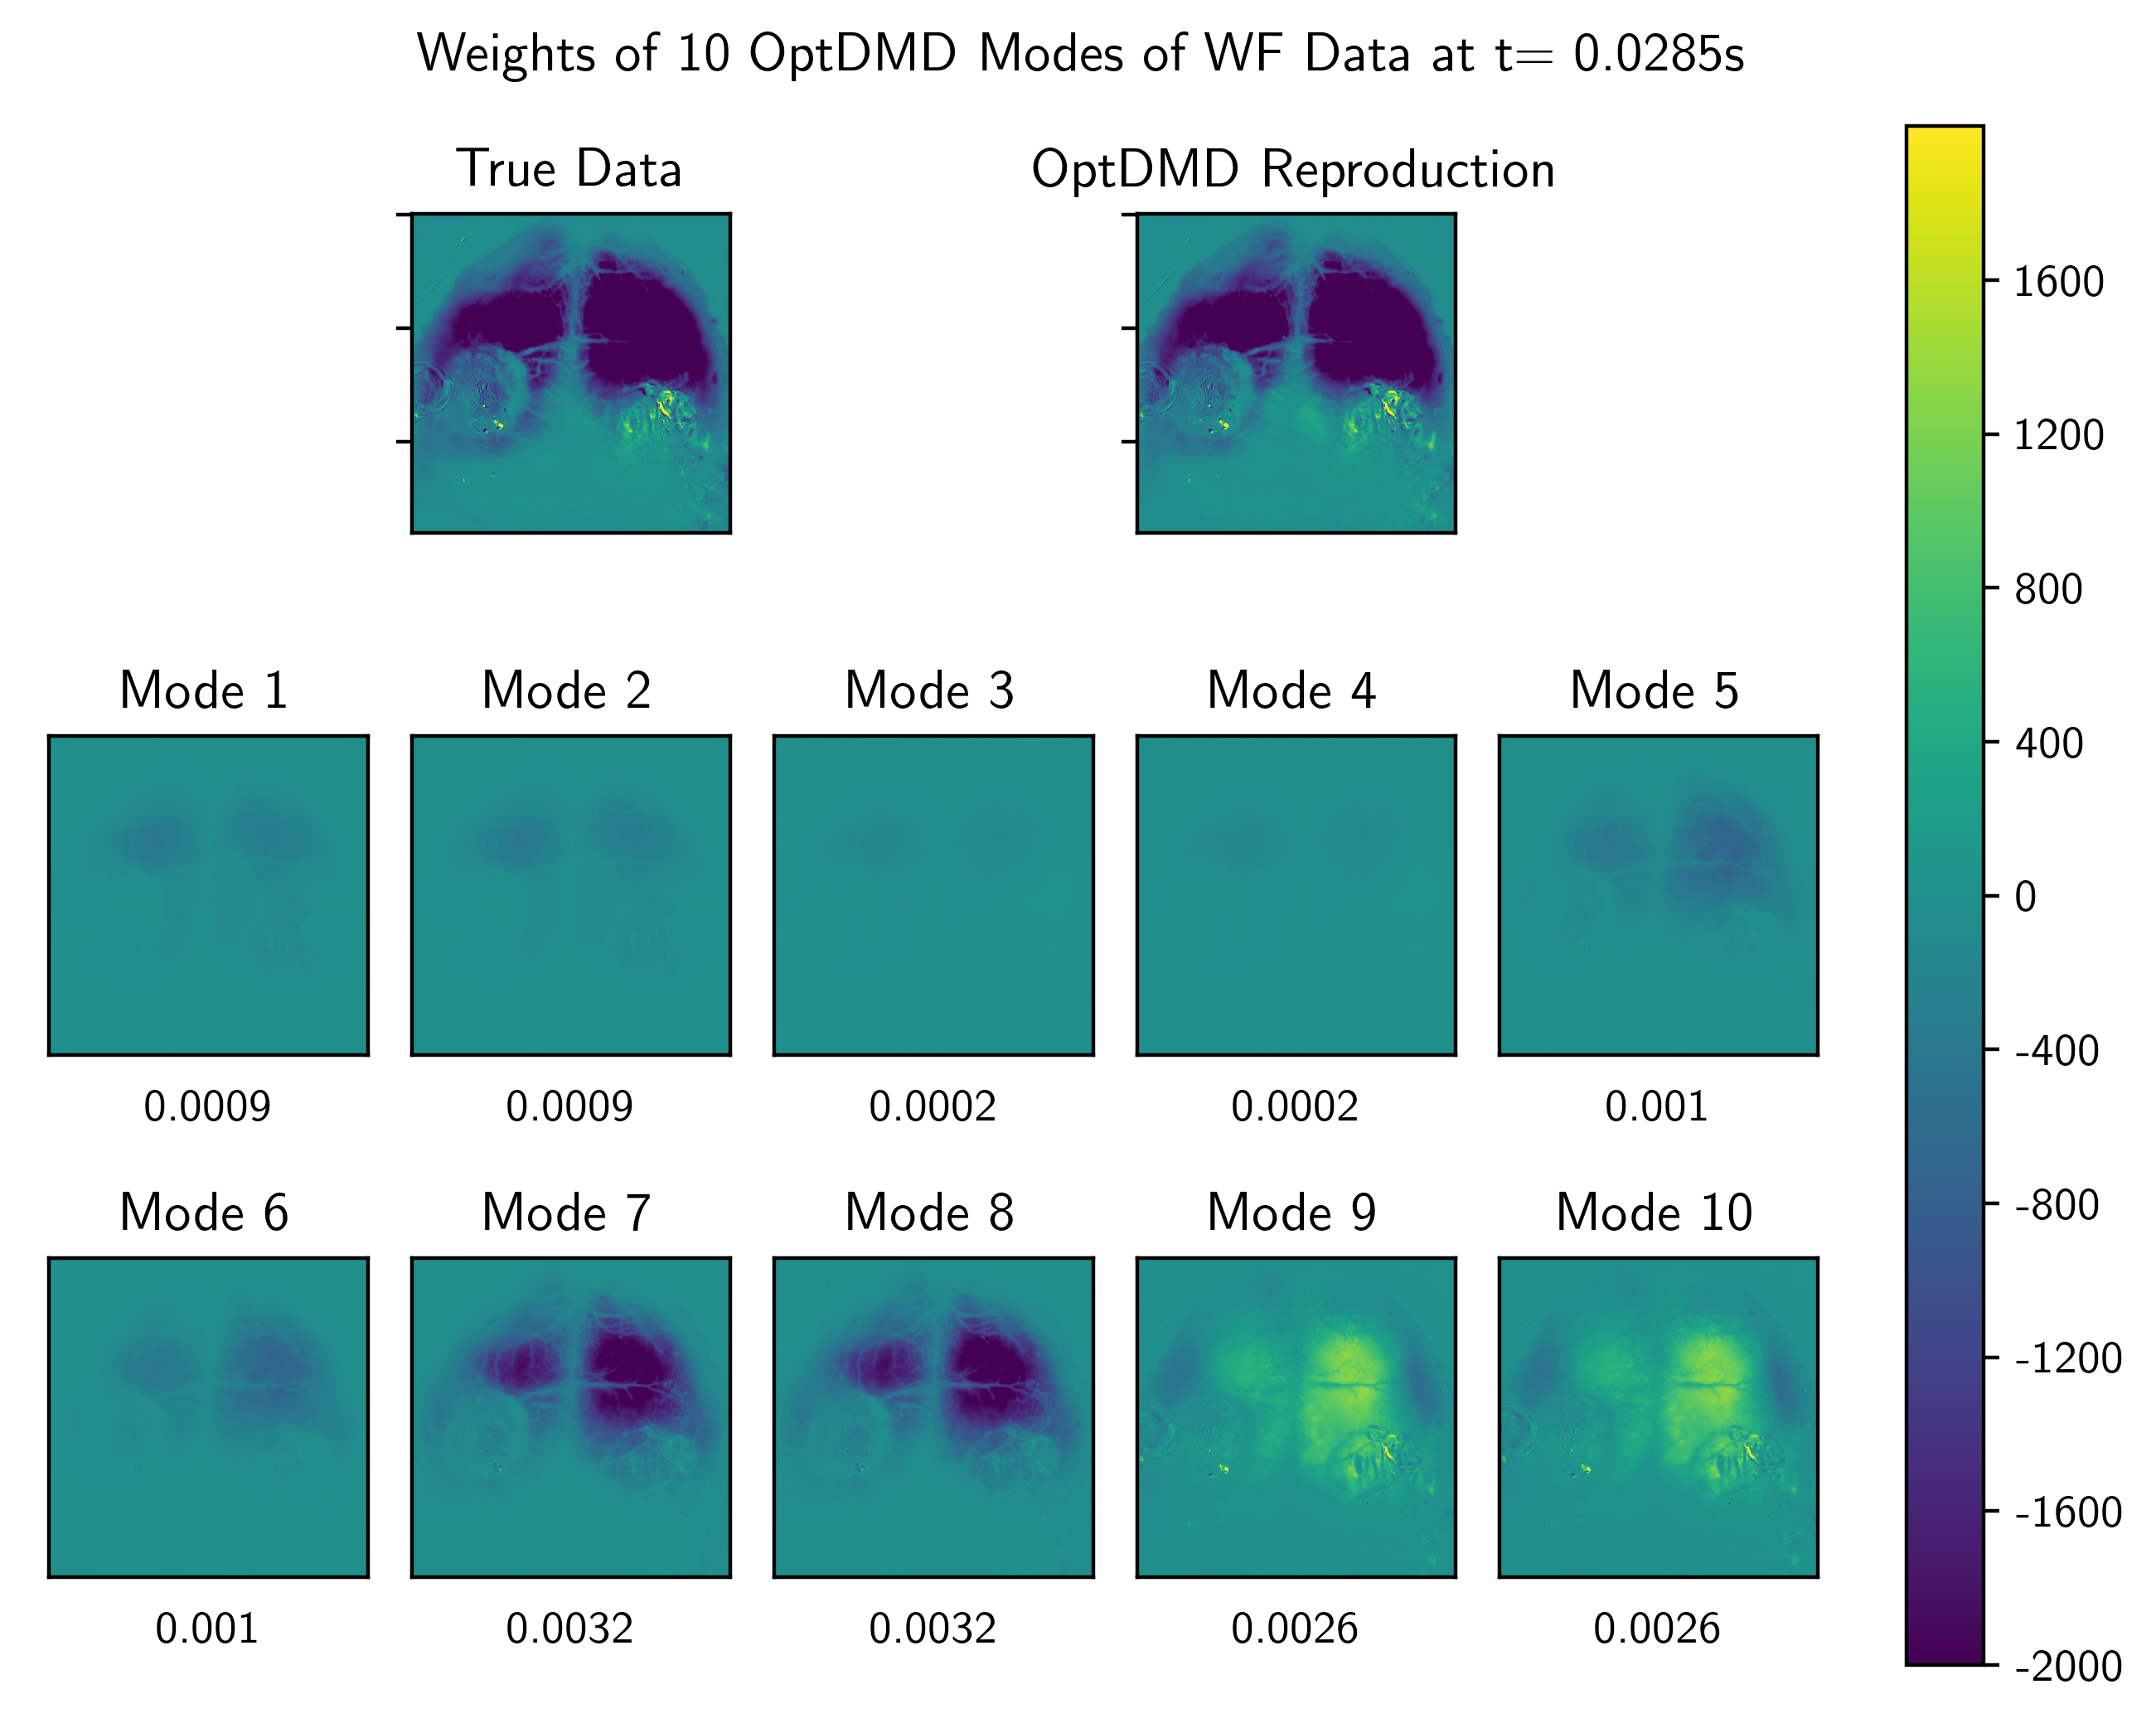

In [42]:
# Import packages for animations
import sys
import warnings
warnings.filterwarnings('ignore')
from matplotlib import animation, rc
rc('animation',html='html5')
# We will create a 3x5 array of plots.
# The top row will be blank except for entry 
fig,ax = plt.subplots(3,5,sharex=True,sharey=True,constrained_layout=True)
ax[0,0].axis('off')
true_ax = ax[0,1].imshow(USV)
ax[0,1].set_title('True Data')
ax[0,2].axis('off')
reproduce_ax = ax[0,3].imshow(np.matmul(top50,np.real(SV_norm[0]*optdmd10.reconstructed_data[:,0]),out=matmul_out))
ax[0,3].set_title("OptDMD Reproduction")
ax[0,4].axis('off')
im = []
for i in range(10):
    USV_reconstruct = np.matmul(top50,np.real(SV_norm[0]*modes[:,0,i]),out=matmul_out)
    if i < 5:
        im.append(ax[1,i].imshow(USV_reconstruct))
        ax[1,i].set_title("Mode " + str(i+1))
        ax[1,i].get_yaxis().set_visible(False)
        ax[1,i].set_xlabel(np.round(np.real(optdmd10.amplitudes[i]),4))
    else:
        im.append(ax[2,i-5].imshow(USV_reconstruct))
        ax[2,i-5].set_title("Mode " + str(i+1))
        ax[2,i-5].get_yaxis().set_visible(False)
        ax[2,i-5].set_xlabel(np.round(np.real(optdmd10.amplitudes[i]),4))
        ax[2,i-5].set_xticks([])
    del USV_reconstruct
dt = 0.0285
fig.suptitle("Weights of 10 OptDMD Modes of WF Data at t= " + str(0*dt)+"s",y=1.05)
fig.colorbar(true_ax,ax=ax,ticks=np.arange(-2000,2000,400),format="%d")
plt.subplots_adjust(bottom=0.001, top=0.9, hspace=0)
def animate(t):
    print("At iteration " + str(t))
    # True data
    USV = np.matmul(top50,SV_norm[0]*SV_normalized[:50,2*t+1],out=matmul_out)
    true_ax.set_data(USV)
    true_ax.set_clim(np.min(-2000),np.max(2000))
    fig.suptitle("Weights of 10 OptDMD Modes of WF Data at t= " + str(np.round((2*t+1)*dt,7))+"s",y=1.05)
    # Reproduction
    USV = np.matmul(top50,np.real(SV_norm[0]*optdmd10.reconstructed_data[:50,2*t+1]),out=matmul_out)
    reproduce_ax.set_data(USV)
    reproduce_ax.set_clim(-2000,2000)
    for i in range(10):
        # Individual modes
        USV = np.matmul(top50,np.real(SV_norm[0]*modes[:,2*t+1,i]),out=matmul_out)
        im[i].set_data(USV)
        im[i].set_clim(-2000,2000)
anim = animation.FuncAnimation(fig,animate,frames=249,save_count=None,repeat=False)
writermp4=animation.FFMpegWriter(fps=6)
anim.save('OptDMD Modes Colorbar Scaled.mp4',writer = writermp4)